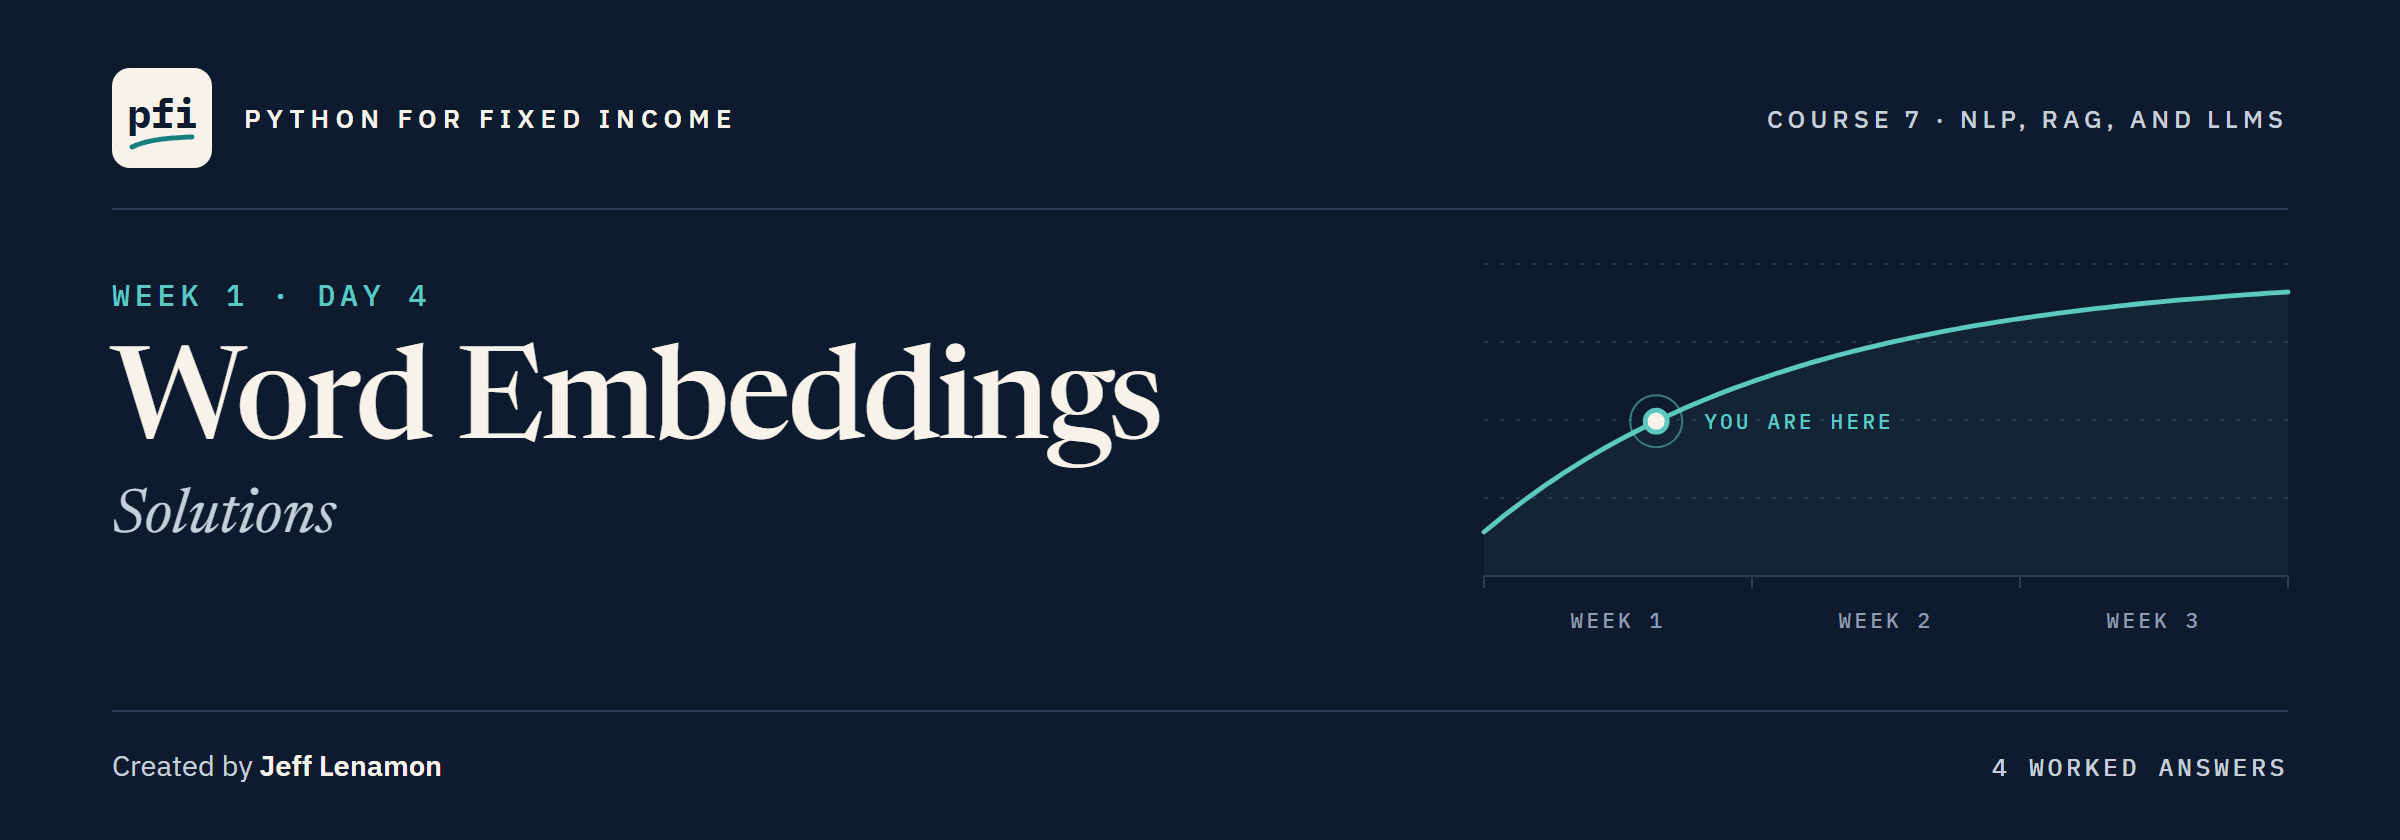

# Word Embeddings: Solutions

Week 1, Day 4. The full notebook with every exercise worked. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course07_nlp_and_llms/week1/day4/04_word_embeddings_solutions.ipynb)

# Problem Statement

## Business Context

Day 3's classifier gives every term its own column, so "bond" and "bonds" share nothing.
A desk wants text features that put related words close together, without a column for each.
Word vectors made by others from billions of words of general English offer that.
Today the desk loads them, checks what they place near its own words, measures what they miss in the Boyd indenture, and sets them to work on Day 3's 8-K question on the same rows.
The 8-K sections and the indenture are real public records, described only.
A nearest word says how a word was used in the vectors' training text, never what it means in a contract.

## Objectives

Load pretrained word vectors from a file and look a word up.
Compare words by cosine and list a word's nearest words, ties broken by the word.
Draw words on a map with an arrow to each word's nearest neighbour.
Do arithmetic on word vectors and read the result with care.
Count the tokens of a document that have no vector.
Turn each section into the mean of its word vectors and fit Day 3's classifier on it.
Show what an average leaves out.
Count which words sit near each other in a document.

## Data Dictionary

`course7_glove_6b_100d.npz`, two arrays:

1. `vectors`: one row of 100 numbers per word, float32
2. `words`: the word of each row, in lower case, in GloVe's order

`course7_8k_items.csv` as Day 3 read it: `filed`, `item` and `text` are used here.

`course7_indentures/boyd_2021.txt` as Day 1 read it.

Made in the notebook: `index_of` (word to row), `unit` (each row at length 1), `X_train` and `X_valid` (one mean vector per section), `missing_train` and `missing_valid` (each section's share of tokens with no row), `vector_model` and `tfidf_model` (Day 3's settings).

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# text: regular expressions, Unicode forms and a counter
import re
import unicodedata
from collections import Counter

# data, charts and a dropdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# scikit-learn: stop words, the vectorizer, the classifier, the pipeline, PCA and the scores
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.metrics import f1_score, recall_score, confusion_matrix

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)

## Reading Files That Are Not Tables

Day 1's `data_file`: the repo's path on your machine, a copy fetched once in Colab.

In [3]:
# the course's text, array, PDF and JSON files: from the repo's data folder, or downloaded once from GitHub in Colab
from urllib.request import urlretrieve


def data_file(name):
    """The path of a course data file on this machine (in Colab, a copy fetched from GitHub the first time)."""
    if not DATA.startswith("https://"):
        return DATA + name
    local = Path(name).name
    if not Path(local).exists():
        urlretrieve(DATA + name, local)
    return local

## Day 1's Pieces in One Cell

Day 1 wrote these lines; they are repeated here as one cell, unchanged.

In [4]:
# Day 1's map of look-alike characters and normalize_text
CHARACTER_MAP = {chr(0x00A0): " ", chr(0x2010): "-", chr(0x2011): "-", chr(0x2013): "-", chr(0x2014): "-",
                 chr(0x2018): "'", chr(0x2019): "'", chr(0x201C): '"', chr(0x201D): '"'}


def normalize_text(text):
    """Text with look-alike characters made plain and white space tidied."""
    text = unicodedata.normalize("NFC", text).translate(str.maketrans(CHARACTER_MAP))
    text = re.sub(r"[^\S\n]*\n\s*", "\n", text)
    text = re.sub(r"[^\S\n]+", " ", text)
    return text.strip()


# Day 1's token and tokenize
TOKEN_PATTERN = r"[a-z0-9]+(?:[-'.][a-z0-9]+)*"


def tokenize(text):
    """The course's tokens of a text, in lower case, after normalize_text."""
    return re.findall(TOKEN_PATTERN, normalize_text(text).lower())


# Day 1's sections and defined terms
SECTION_PATTERN = r"^(?:Section|SECTION) (?P<number>\d+\.\d+)\.? (?P<title>[A-Z\[][^\n]*?)\.?$"


def find_sections(text):
    """The sections of an indenture, in the order of the text: number as text, title, start and end."""
    found = {}
    for heading in re.finditer(SECTION_PATTERN, text, flags=re.MULTILINE):
        found[heading["number"]] = {"number": heading["number"], "title": heading["title"], "start": heading.start()}
    sections = pd.DataFrame(found.values()).sort_values("start", ignore_index=True)
    sections["end"] = sections["start"].shift(-1, fill_value=len(text))
    return sections


def defined_terms(text):
    """Every "Term" means or "Term" has the meaning in a text: the term, where it starts, and which form."""
    pattern = r'"(?P<term>[A-Z0-9][^"\n]{0,100}?)"\s+(?P<kind>means|has the meaning)\b'
    rows = [{"term": found["term"], "start": found.start(), "kind": found["kind"]} for found in re.finditer(pattern, text)]
    return pd.DataFrame(rows)


# Day 1's source line
def boyd_source(section=None):
    """Print the source line of the Boyd indenture, or of one of its sections."""
    where = f", Section {section}" if section else ""
    print("Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed "
          f"2021-06-08, accession 0001193125-21-185495{where}.")

# Loading the Data

## The Word Vectors

A **word vector** (or **word embedding**) is a row of numbers for one word, made so that words used in the same company get similar rows.
**GloVe** is one published set of them, made from general English text, and the course's file keeps 44,558 of its words at 100 numbers each.
They are **pretrained**: someone else made them once, and today only reads them.
An `.npz` file holds several named arrays, and `.files` lists their names (Course 1).

In [5]:
# the course's GloVe file: its arrays, then the vectors and the words as a list
glove = np.load(data_file("course7_glove_6b_100d.npz"))
print(glove.files)
vectors = glove["vectors"]
words = glove["words"].tolist()

['vectors', 'words']


## The Indenture and the 8-K Sections

In [6]:
# Day 1's indenture, made plain, and its sections by number
boyd = normalize_text(Path(data_file("course7_indentures/boyd_2021.txt")).read_text(encoding="utf-8"))
sections = find_sections(boyd).set_index("number")
section_412 = boyd[sections.loc["4.12", "start"]:sections.loc["4.12", "end"]]
print(len(sections), "sections | Section 4.12:", sections.loc["4.12", "title"])

# Day 3's sections, split by filing date
eightk = pd.read_csv(DATA + "course7_8k_items.csv", dtype={"item": str})
LABELS = sorted(eightk["item"].unique())
train = eightk[eightk["filed"] <= "2023-12-31"]
valid = eightk[(eightk["filed"] > "2023-12-31") & (eightk["filed"] <= "2024-12-31")]
print("training", len(train), "| validation", len(valid), "| test, closed until Day 10:", (eightk["filed"] > "2024-12-31").sum())

107 sections | Section 4.12: Limitation on Indebtedness
training 3650 | validation 741 | test, closed until Day 10: 735


# Data Overview

## Shape and Type

In [7]:
# one row of 100 numbers per word, stored as float32 (Course 5's float32), its size (.nbytes, in bytes), and the words that repeat
print(vectors.shape, vectors.dtype, f"| {vectors.nbytes / 1e6:.1f} MB |", len(words) - len(set(words)), "words repeat")

(44558, 100) float32 | 17.8 MB | 0 words repeat


## The Order of the Words

In [8]:
# the first twelve rows' words, and how many words hold a capital letter
print(words[:12])
print(sum(word != word.lower() for word in words), "words hold a capital letter")

['the', ',', '.', 'of', 'to', 'and', 'in', 'a', '"', "'s", 'for', '-']
0 words hold a capital letter


The rows run in **frequency order**, most frequent first, and punctuation and `'s` are words of their own.

No word holds a capital: the vectors are **uncased**, so every lookup uses the lower-case form, as Day 1's tokens are.

## One Word's Row

In [9]:
# a dictionary from word to row, built once, then the row of "bond"
index_of = {word: row for row, word in enumerate(words)}
bond = vectors[index_of["bond"]]
print("row", index_of["bond"], "| first three numbers", bond[:3].round(4), f"| length {np.linalg.norm(bond):.4f}")

row 1846 | first three numbers [0.8918 0.3513 0.1522] | length 5.8566


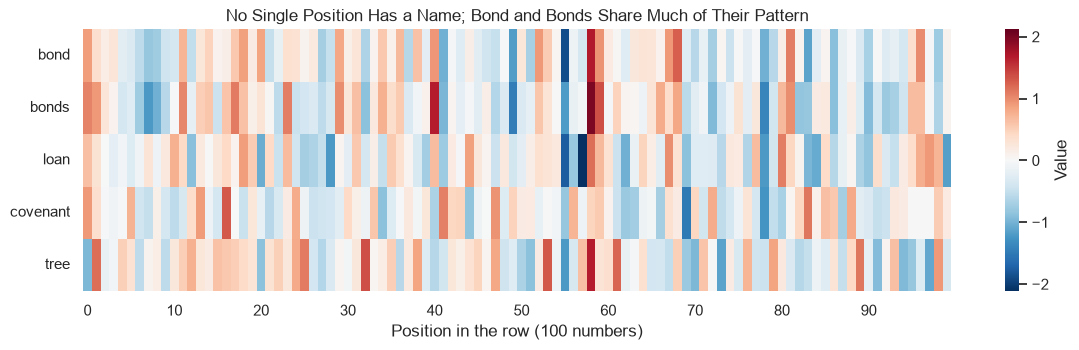

In [10]:
# five words' 100 numbers as five strips on one colour scale, blue below zero and red above
five = ["bond", "bonds", "loan", "covenant", "tree"]
strips = vectors[[index_of[word] for word in five]]
plt.figure(figsize=(14, 3.4))
sns.heatmap(strips, cmap="RdBu_r", vmin=-np.abs(strips).max(), vmax=np.abs(strips).max(), yticklabels=five, xticklabels=10,
            cbar_kws={"label": "Value"})
plt.yticks(rotation=0)
plt.xlabel("Position in the row (100 numbers)")
plt.title("No Single Position Has a Name; Bond and Bonds Share Much of Their Pattern")
plt.show()

No position has a name: a word's place comes from all 100 numbers together.

Rows that look alike are what the next sections measure.

## Rows at Length One

`unit` holds every row divided by its length, in float64 so the last digits never move.
Then `unit @ unit[row]` is Day 2's cosine of one word against every word at once.

In [11]:
# every row in float64, divided by its own length
unit = vectors.astype(np.float64)
unit = unit / np.linalg.norm(unit, axis=1, keepdims=True)
print(np.linalg.norm(unit[:3], axis=1))

[1. 1. 1.]


**A word is now a direction, and every comparison from here is a cosine of unit rows.**

# Words Close Together

## Two Words, One Cosine

In [12]:
# Day 2's cosine: the dot product of two unit rows, and its angle in degrees
for other in ["bonds", "loan"]:
    cosine = unit[index_of["bond"]] @ unit[index_of[other]]
    print(f"bond and {other}: cosine {cosine:.4f}, {np.degrees(np.arccos(cosine)):.1f} degrees")

bond and bonds: cosine 0.8374, 33.1 degrees
bond and loan: cosine 0.5232, 58.5 degrees


**Predict 1**

Q. Every indenture prints "bond" and "covenant" in the same pages. What is the cosine of "bond" and "covenant" in these vectors? Write down a number.

## Bond and Covenant

In [13]:
# the same cosine for bond and covenant
cosine = unit[index_of["bond"]] @ unit[index_of["covenant"]]
print(f"bond and covenant: cosine {cosine:.4f}, {np.degrees(np.arccos(cosine)):.1f} degrees")

bond and covenant: cosine 0.0265, 88.5 degrees


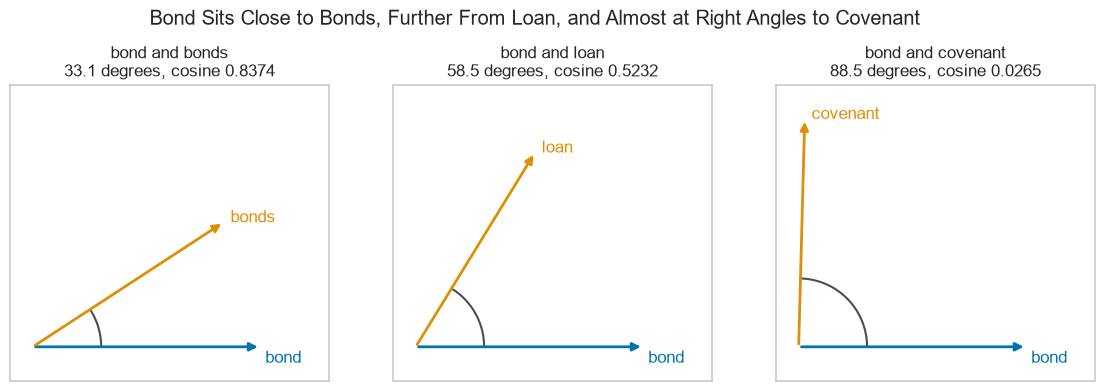

In [14]:
# Day 2's angle fan: each pair as two arrows of length 1 at their true angle
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
for ax, other in zip(axes, ["bonds", "loan", "covenant"]):
    cosine = unit[index_of["bond"]] @ unit[index_of[other]]
    angle = np.arccos(cosine)
    ax.annotate("", xy=(1, 0), xytext=(0, 0), arrowprops={"arrowstyle": "-|>", "color": "C0", "lw": 2})
    ax.annotate("", xy=(np.cos(angle), np.sin(angle)), xytext=(0, 0), arrowprops={"arrowstyle": "-|>", "color": "C1", "lw": 2})
    arc = np.linspace(0, angle, 40)
    ax.plot(0.3 * np.cos(arc), 0.3 * np.sin(arc), color="0.3")
    ax.text(1.02, -0.07, "bond", color="C0")
    ax.text(np.cos(angle) + 0.03, np.sin(angle), other, color="C1")
    ax.set(xlim=(-0.1, 1.3), ylim=(-0.15, 1.15), aspect="equal", xticks=[], yticks=[],
           title=f"bond and {other}\n{np.degrees(angle):.1f} degrees, cosine {cosine:.4f}")
fig.suptitle("Bond Sits Close to Bonds, Further From Loan, and Almost at Right Angles to Covenant")
plt.show()

Two words every indenture prints side by side sit almost at right angles in general English.

## `nearest_words`

A word's **nearest words** are the rows with the largest cosine to its row.
`np.lexsort` (Day 2) sorts by cosine and breaks a tie by the word, and the word itself is left out.

In [15]:
# the k words with the largest cosine to a word, ties broken by the word, cosines at 3 decimals
def nearest_words(word, k=5):
    """The k words nearest a word by cosine, the word itself left out, as (word, cosine) pairs."""
    cosines = unit @ unit[index_of[word]]
    order = np.lexsort((words, -cosines))
    order = order[order != index_of[word]][:k]
    return [(words[row], round(float(cosines[row]), 3)) for row in order]


for word in ["bond", "default", "inflation"]:
    print(word, nearest_words(word))

bond [('bonds', 0.837), ('treasury', 0.719), ('benchmark', 0.685), ('interest', 0.684), ('30-year', 0.683)]
default [('debt', 0.65), ('borrower', 0.642), ('borrowers', 0.641), ('issuer', 0.632), ('defaults', 0.631)]
inflation [('rate', 0.783), ('rates', 0.781), ('unemployment', 0.75), ('inflationary', 0.744), ('growth', 0.744)]


No desk text went into these vectors, and still "bond" sits among bond-market words, "default" among borrowers and issuers, "inflation" among rates and unemployment.

**The vectors place the market's own words together: that is what they offer as features.**

**Predict 2**

Q. Write down three words you expect nearest "covenant" in these vectors.

## Covenant

In [16]:
# the five nearest words of covenant
print(nearest_words("covenant"))

[('lutheran', 0.558), ('charter', 0.555), ('covenants', 0.535), ('enshrined', 0.504), ('principles', 0.503)]


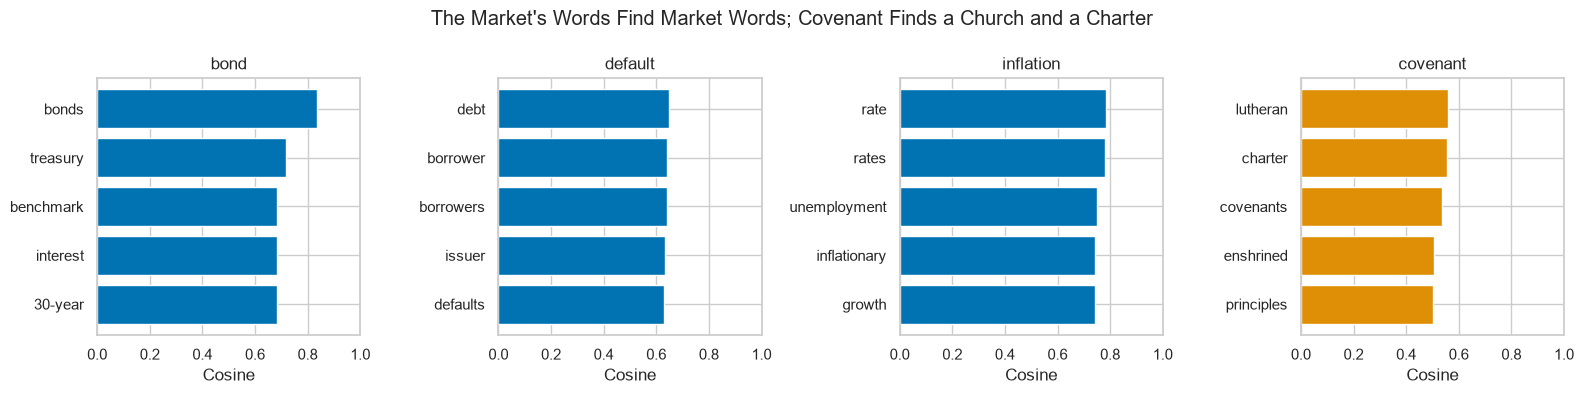

In [17]:
# the five nearest words of four words, one panel each
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True)
for ax, word in zip(axes, ["bond", "default", "inflation", "covenant"]):
    pairs = nearest_words(word)
    ax.barh([near for near, _ in pairs][::-1], [cosine for _, cosine in pairs][::-1], color="C1" if word == "covenant" else "C0")
    ax.set(title=word, xlim=(0, 1), xlabel="Cosine")
fig.suptitle("The Market's Words Find Market Words; Covenant Finds a Church and a Charter")
plt.tight_layout()
plt.show()

In general English a covenant is a church's or a charter's: the vectors carry the company the word kept in their training text.

## Your Turn: Any Word

Pick a desk word and see its five nearest words.

In [18]:
# the five nearest words of any word in the list, as bars
def show_nearest(word="senior"):
    pairs = nearest_words(word)
    plt.barh([near for near, _ in pairs][::-1], [cosine for _, cosine in pairs][::-1])
    plt.xlim(0, 1)
    plt.xlabel(f"Cosine with {word}")
    plt.title(f"The Five Words Nearest {word.title()} in These Vectors")
    plt.show()


interact(show_nearest, word=["senior", "coupon", "maturity", "callable", "subordinated", "liquidity", "issuer",
                             "refinancing", "par", "redemption"]);

interactive(children=(Dropdown(description='word', options=('senior', 'coupon', 'maturity', 'callable', 'subor…

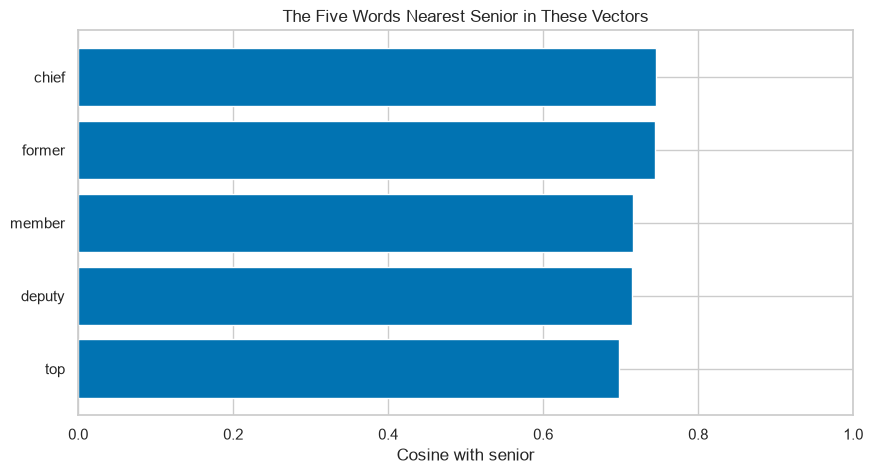

In [19]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
show_nearest("senior")

"senior" sits with chief, former and deputy: in general English seniority is a person's.

Try "redemption" and "subordinated": one finds a sermon's words, the other the words of a bond prospectus.

**Predict 3**

Q. The next map places 33 desk words in four groups: credit, rates, inflation, and eight legal words (covenant, indenture, trustee, lien, collateral, obligation, note, notes). From each word an arrow points to its nearest of the other 32. Sketch where the legal words land among the other three groups, and where their arrows point.

## A Map of Desk Words

In [20]:
# 33 desk words in four groups, each word's group, and the cosine of every pair
GROUPS = {"credit": ["default", "bankruptcy", "debt", "loan", "loans", "bond", "bonds", "credit", "lender", "creditors"],
          "rates": ["rate", "rates", "yield", "yields", "interest", "borrowing", "spread", "spreads"],
          "inflation": ["inflation", "prices", "price", "deflation", "wages", "unemployment", "cpi"],
          "legal": ["covenant", "indenture", "trustee", "lien", "collateral", "obligation", "note", "notes"]}
map_words = [word for group in GROUPS.values() for word in group]
group_of = np.array([name for name, group in GROUPS.items() for _ in group])
pair_cosine = unit[[index_of[word] for word in map_words]] @ unit[[index_of[word] for word in map_words]].T

# each word's nearest of the other 32 (a word's cosine with itself set to -1 first)
others = pair_cosine.copy()
np.fill_diagonal(others, -1)
nearest = others.argmax(axis=1)

The arrows are measured in all 100 numbers.
To put the words on a page, Course 4's Day 14 PCA keeps the two directions along which the 33 rows spread most.

In [21]:
# demonstration: two principal components fitted to the 33 rows, only to place the words on the page
pca = PCA(n_components=2).fit(vectors[[index_of[word] for word in map_words]].astype(np.float64))
place = pca.transform(vectors[[index_of[word] for word in map_words]].astype(np.float64))
print(f"{pca.explained_variance_ratio_.sum():.4f} of the 33 rows' variance is kept on the page")

0.3181 of the 33 rows' variance is kept on the page


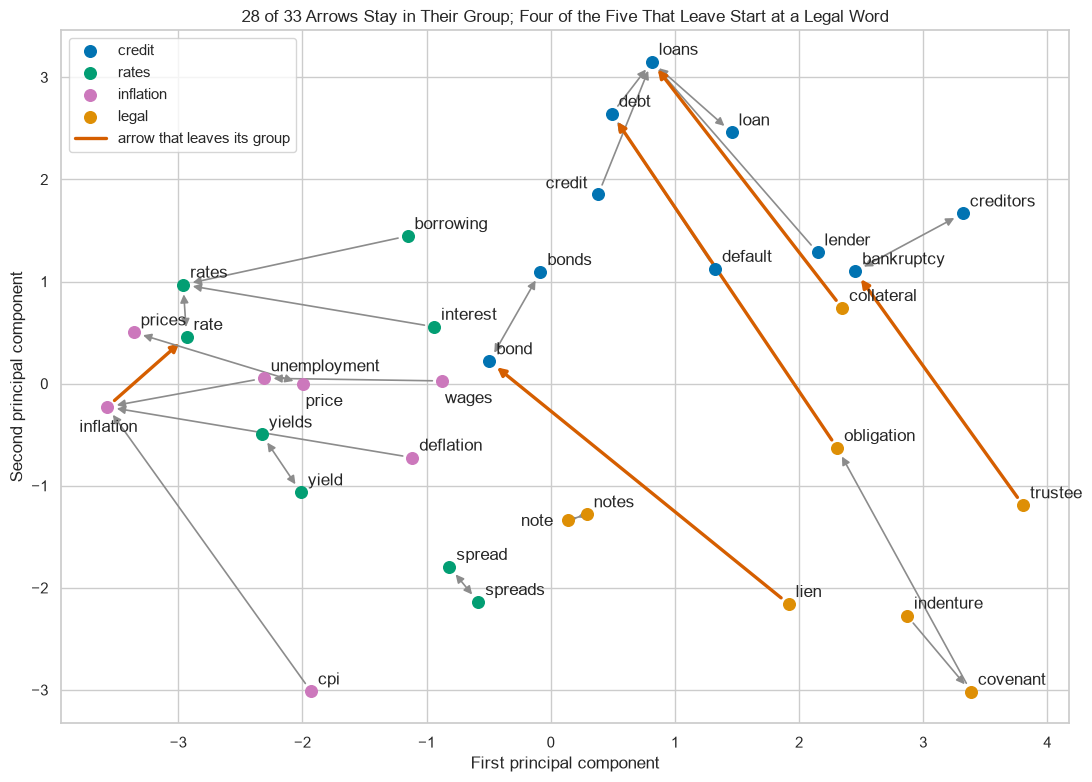

In [22]:
# each word a dot in its group's colour, an arrow to its nearest word, one double-headed line for a mutual pair,
# and the arrows that leave their group in the accent colour
colour = {"credit": "C0", "rates": "C2", "inflation": "C4", "legal": "C1"}
fig, ax = plt.subplots(figsize=(13, 9))
for i, j in enumerate(nearest):
    leaves = group_of[i] != group_of[j]
    if nearest[j] == i and i > j:
        continue
    style = "<|-|>" if nearest[j] == i else "-|>"
    ax.annotate("", xy=place[j], xytext=place[i], arrowprops={"arrowstyle": style, "color": "C3" if leaves else "0.55",
                                                              "lw": 2.4 if leaves else 1.2, "shrinkA": 7, "shrinkB": 7})
for name in GROUPS:
    ax.scatter(*place[group_of == name].T, s=70, color=colour[name], label=name, zorder=3)
# each word's label beside its dot, a few moved so they do not cover a neighbour
moved = {"note": (-34, -4), "price": (2, -16), "inflation": (-20, -18), "wages": (2, -16), "credit": (-38, 4)}
for word, (x, y) in zip(map_words, place):
    ax.annotate(word, (x, y), xytext=moved.get(word, (5, 5)), textcoords="offset points", fontsize=12)
ax.plot([], [], color="C3", lw=2.4, label="arrow that leaves its group")
ax.legend(loc="best")
ax.set(xlabel="First principal component", ylabel="Second principal component",
       title="28 of 33 Arrows Stay in Their Group; Four of the Five That Leave Start at a Legal Word")
plt.show()

Read the arrows, not the distances: the plane only places the words, so an arrow may pass a word that looks nearer.

A double-headed line is a pair that are each other's nearest.

"note" and "notes" are such a pair too, but their dots sit so close that the line between them is hidden.

### Interpretation of the Map

In [23]:
# how many arrows stay in their group; each group's mean cosine inside it and with the other groups
# (np.ix_ picks the block of rows and columns two lists name)
print((group_of[nearest] == group_of).sum(), "of 33 arrows point inside their group")
for name in GROUPS:
    inside = group_of == name
    block = pair_cosine[np.ix_(inside, inside)]
    mean_inside = (block.sum() - inside.sum()) / (inside.sum() * (inside.sum() - 1))
    print(f"{name}: inside {mean_inside:.4f} | with the others {pair_cosine[np.ix_(inside, ~inside)].mean():.4f}")

# the arrows that leave their group
for i, j in enumerate(nearest):
    if group_of[i] != group_of[j]:
        print(f"{map_words[i]} ({group_of[i]}) to {map_words[j]} ({group_of[j]}): {pair_cosine[i, j]:.4f}")

28 of 33 arrows point inside their group
credit: inside 0.5710 | with the others 0.3500
rates: inside 0.5667 | with the others 0.3599
inflation: inside 0.5407 | with the others 0.3218
legal: inside 0.1998 | with the others 0.2060
inflation (inflation) to rate (rates): 0.7825
trustee (legal) to bankruptcy (credit): 0.4464
lien (legal) to bond (credit): 0.2413
collateral (legal) to loans (credit): 0.5829
obligation (legal) to debt (credit): 0.5686


Credit, rates and inflation each sit much closer inside than with the others.

The legal words sit no closer to each other than to the rest, and four of the five arrows that leave a group start at a legal word.

**General-English vectors place the market's words together and scatter the contract's.**

# Arithmetic on Word Vectors

## `bonds - bond + loan`

An **analogy** adds the **offset** from one word to another onto a third: `bonds - bond + loan` asks for the word that sits from "loan" as "bonds" sits from "bond".
The sum is made of unit rows, so each word's direction counts and its length does not.

In [24]:
# the k words nearest b - a + c on unit rows, the three inputs left out, cosines at 3 decimals
def analogy(a, b, c, k=3):
    """The k words nearest b - a + c, as (word, cosine) pairs, with a, b and c left out."""
    target = unit[index_of[b]] - unit[index_of[a]] + unit[index_of[c]]
    cosines = unit @ target / np.linalg.norm(target)
    order = [row for row in np.lexsort((words, -cosines)) if words[row] not in (a, b, c)]
    return [(words[row], round(float(cosines[row]), 3)) for row in order[:k]]


print("bonds - bond + loan:", analogy("bond", "bonds", "loan"))

# where the three inputs would rank if they were kept in
target = unit[index_of["bonds"]] - unit[index_of["bond"]] + unit[index_of["loan"]]
ranking = list(np.lexsort((words, -(unit @ target))))
print("kept in:", {word: ranking.index(index_of[word]) + 1 for word in ["bond", "bonds", "loan"]})

bonds - bond + loan: [('loans', 0.788), ('debt', 0.67), ('repay', 0.658)]
kept in: {'bond': 1112, 'bonds': 14, 'loan': 1}


"loans" comes first, the plural the offset aims at.

Kept in, "loan" itself would be nearest: an analogy only works once its inputs are left out.

## `lender - loan + bond`

In [25]:
# the same arithmetic for a holder of a bond, and where two desk words rank
print("lender - loan + bond:", analogy("loan", "lender", "bond"))
target = unit[index_of["lender"]] - unit[index_of["loan"]] + unit[index_of["bond"]]
ranking = list(np.lexsort((words, -(unit @ target))))
print({word: ranking.index(index_of[word]) + 1 for word in ["investor", "bondholders"]})

lender - loan + bond: [('benchmark', 0.576), ('shares', 0.543), ('insurer', 0.543)]
{'investor': 12, 'bondholders': 397}


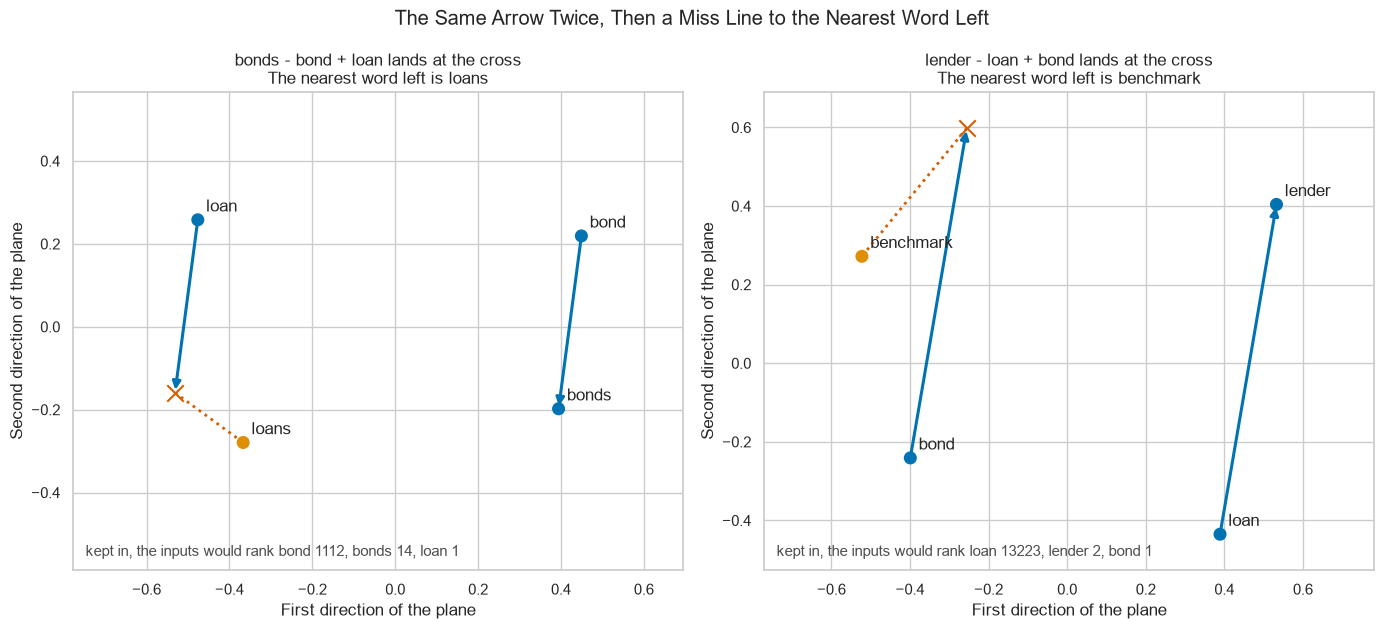

In [26]:
# each analogy drawn in a plane fitted to its four unit rows (demonstration): the arrow a to b, the same arrow from c,
# its arrival as a cross, and a dotted line to the nearest word left
fig, axes = plt.subplots(1, 2, figsize=(14, 6.4))
for ax, (a, b, c) in zip(axes, [("bond", "bonds", "loan"), ("loan", "lender", "bond")]):
    d = analogy(a, b, c, k=1)[0][0]
    four = unit[[index_of[word] for word in (a, b, c, d)]]
    plane = PCA(n_components=2).fit(four)
    points = plane.transform(four)
    target = unit[index_of[b]] - unit[index_of[a]] + unit[index_of[c]]
    arrival = plane.transform([target])[0]
    ranking = list(np.lexsort((words, -(unit @ target))))
    ranks = ", ".join(f"{word} {ranking.index(index_of[word]) + 1}" for word in (a, b, c))
    ax.text(0.02, 0.03, f"kept in, the inputs would rank {ranks}", transform=ax.transAxes, fontsize=11, color="0.3")
    for start, end in [(points[0], points[1]), (points[2], arrival)]:
        ax.annotate("", xy=end, xytext=start, arrowprops={"arrowstyle": "-|>", "color": "C0", "lw": 2.2})
    ax.scatter(*points.T, s=70, color=["C0", "C0", "C0", "C1"], zorder=3)
    ax.scatter(*arrival, marker="x", s=140, color="C3", zorder=3)
    ax.plot([arrival[0], points[3][0]], [arrival[1], points[3][1]], linestyle=":", color="C3", lw=2)
    for word, point in zip((a, b, c, d), points):
        ax.annotate(word, point, xytext=(6, 6), textcoords="offset points", fontsize=12)
    # adjustable="datalim" keeps both panels the same size while each keeps equal scales on its two axes
    ax.set(aspect="equal", adjustable="datalim", xlabel="First direction of the plane", ylabel="Second direction of the plane",
           title=f"{b} - {a} + {c} lands at the cross\nThe nearest word left is {d}")
    ax.margins(0.25)
fig.suptitle("The Same Arrow Twice, Then a Miss Line to the Nearest Word Left")
plt.tight_layout()
plt.show()

A linear plane keeps equal arrows equal and parallel, so the two arrows in each panel are exactly one arrow drawn twice.

The cross never lands on a word: the arithmetic always returns the nearest word left, close or far.

**Analogies make a picture, not a fact: the course reads no answer off them and uses the vectors only as features.**

# From Words to a Section

## The Mean of a Section's Word Vectors

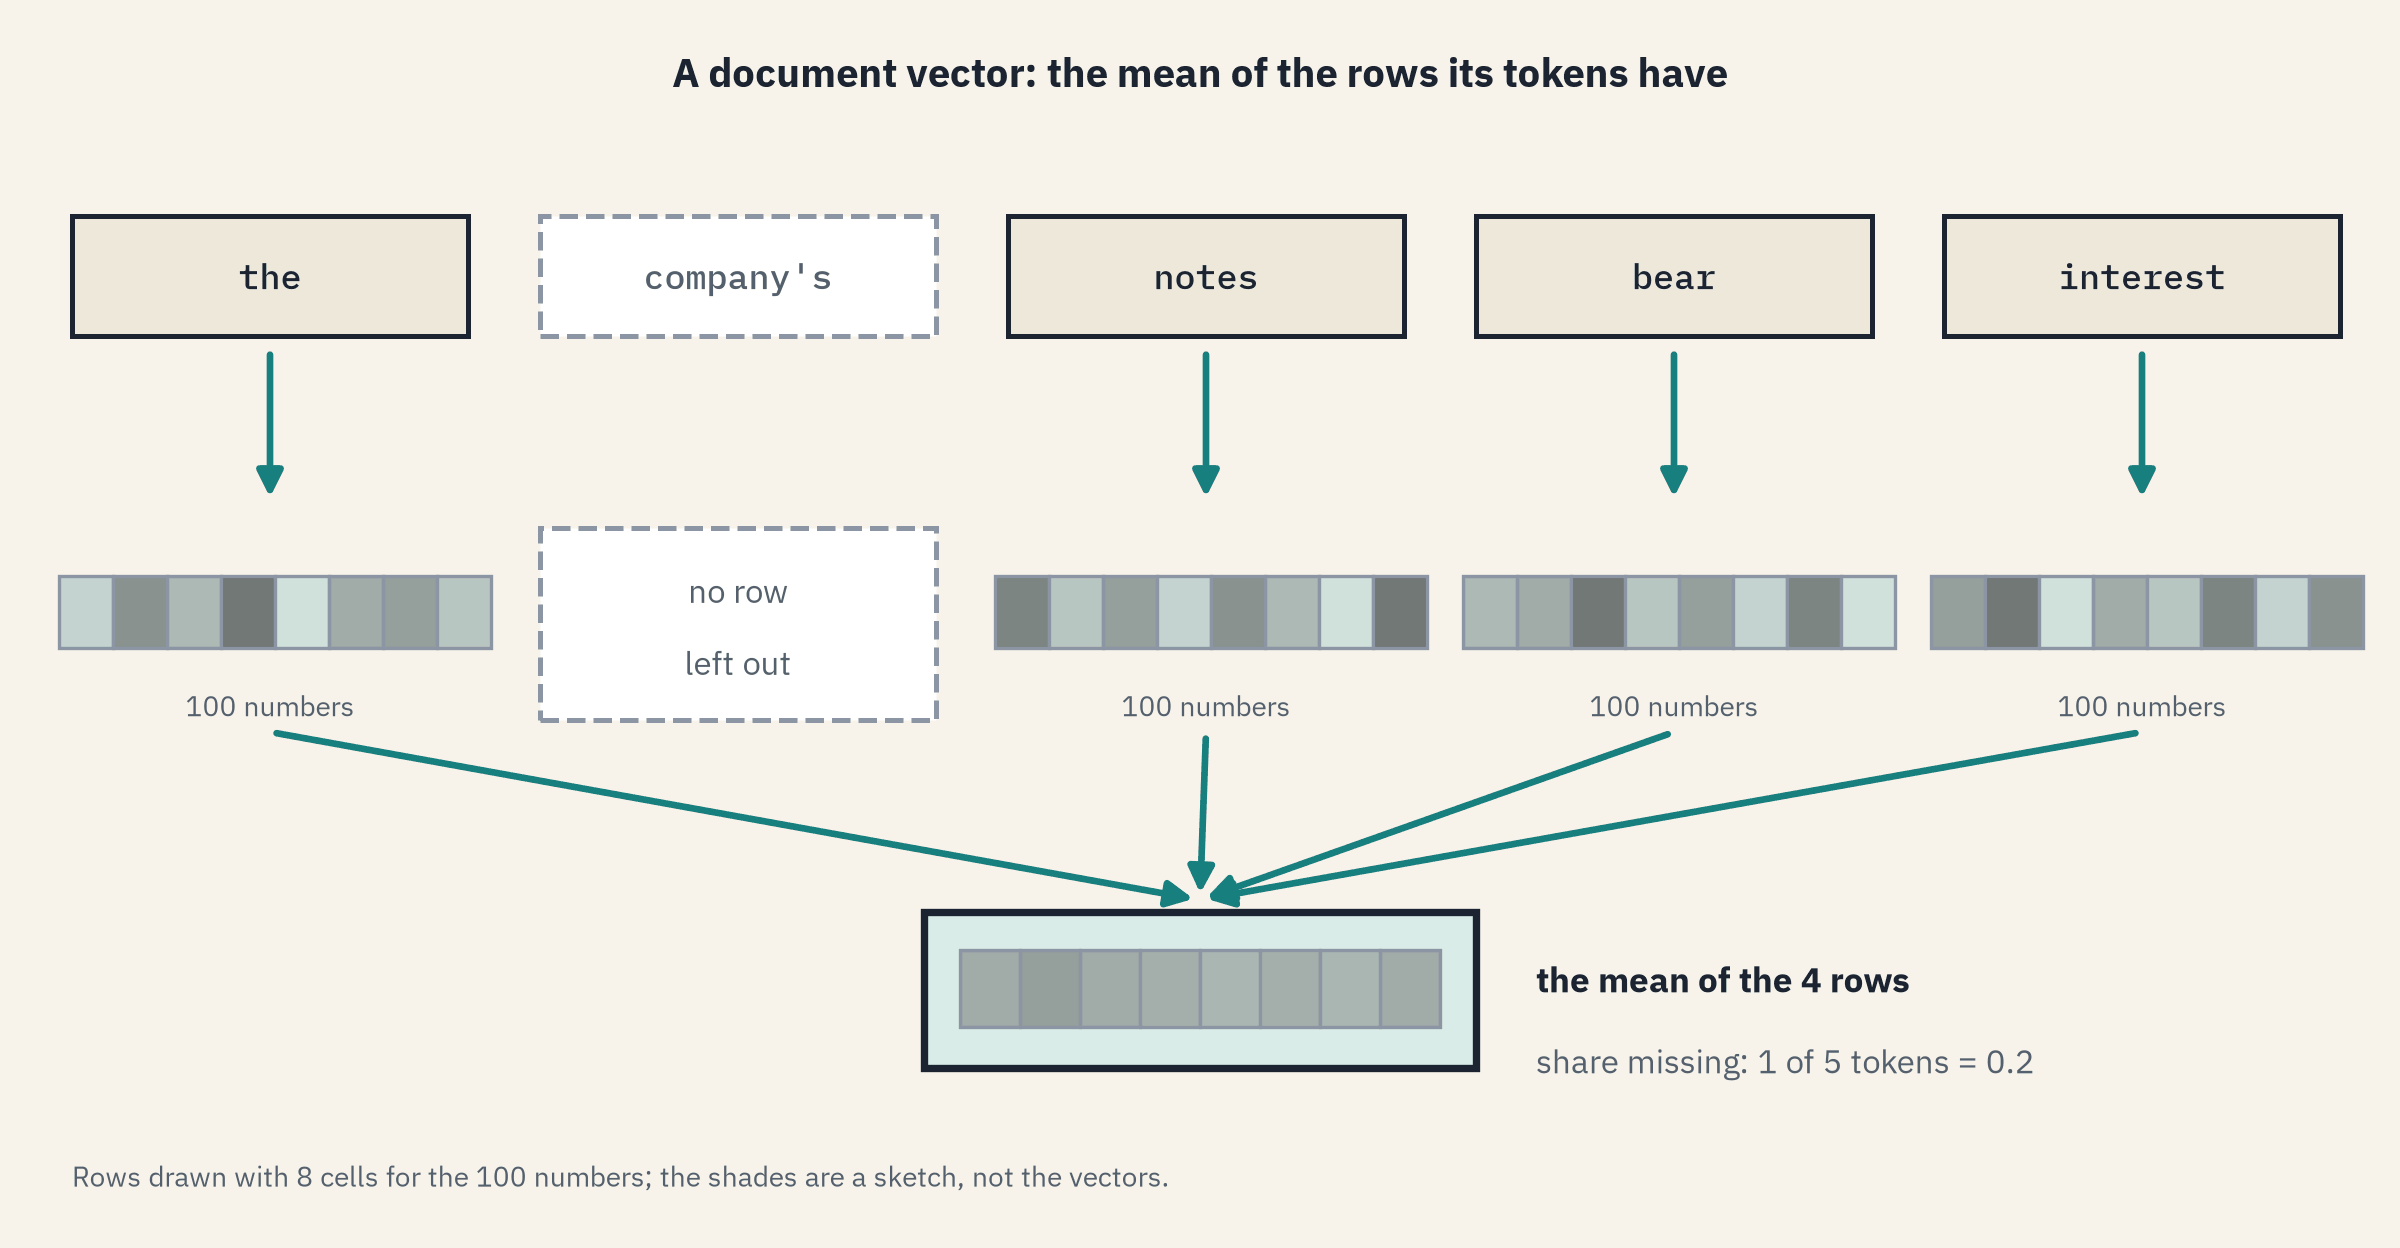

A **document vector** is the mean of the word vectors of a text's tokens, so a section of any length becomes one row of 100 numbers.
A token with no row is **out of vocabulary**: the mean leaves it out, and its **missing share** says how many were left out.

In [27]:
# Day 1's tokens, the mean of the raw rows of those found (in float64), and the share not found
def document_vector(text):
    """The mean word vector of a text's tokens that have a row, and the share of its tokens with none."""
    tokens = tokenize(text)
    found = [index_of[token] for token in tokens if token in index_of]
    return vectors[found].astype(np.float64).mean(axis=0), 1 - len(found) / len(tokens)


vector, share = document_vector("The Company's Notes bear interest")
print(vector.shape, f"| share missing {share:.4f}")

(100,) | share missing 0.2000


## Every Training and Validation Section

In [28]:
# one mean vector and one missing share per section, in the two open roles
train_pairs = [document_vector(text) for text in train["text"]]
valid_pairs = [document_vector(text) for text in valid["text"]]
X_train = np.array([vector for vector, _ in train_pairs])
X_valid = np.array([vector for vector, _ in valid_pairs])
missing_train = np.array([share for _, share in train_pairs])
missing_valid = np.array([share for _, share in valid_pairs])
print(X_train.shape, X_valid.shape)

(3650, 100) (741, 100)


mean share missing: training 0.0186, validation 0.0188 | validation median 0.0167, largest 0.0971, 155 with none


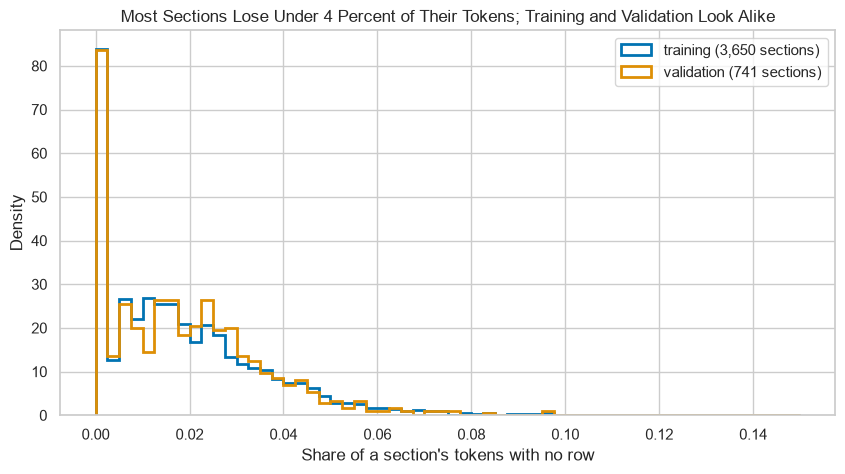

In [29]:
# the share of each section's tokens with no row, training and validation
print(f"mean share missing: training {missing_train.mean():.4f}, validation {missing_valid.mean():.4f}",
      f"| validation median {np.median(missing_valid):.4f}, largest {missing_valid.max():.4f}, {(missing_valid == 0).sum()} with none")
bins = np.linspace(0, 0.15, 61)
# histtype="step" draws each histogram as an outline, so the two can overlap
plt.hist(missing_train, bins=bins, density=True, histtype="step", lw=2, label="training (3,650 sections)")
plt.hist(missing_valid, bins=bins, density=True, histtype="step", lw=2, label="validation (741 sections)")
plt.legend()
plt.xlabel("Share of a section's tokens with no row")
plt.ylabel("Density")
plt.title("Most Sections Lose Under 4 Percent of Their Tokens; Training and Validation Look Alike")
plt.show()

In [30]:
# the training tokens most often with no row
print(Counter(token for text in train["text"] for token in tokenize(text) if token not in index_of).most_common(5))

[("company's", 3060), ('hereunto', 689), ('n.a', 200), ('5550', 177), ('wholly-owned', 167)]


"company's" leads: GloVe keeps "'s" apart as a word of its own, while Day 1's tokens keep it on the word.

**Every section is now 100 numbers, whatever its length.**

# Classifying 8-K Items With Word Vectors

**Predict 4**

Q. Fit Day 3's classifier on the 100 numbers of each training section and score the validation sections. Its macro F1 lies between the majority baseline's 0.0297 and Day 3's TF-IDF model's 0.9429: where? Write down a number.

## Day 3's Classifier on 100 Numbers

The model is fitted on the sections filed 2019 to 2023 and scored on 2024; the 2025 sections stay closed until Day 10, and the indenture is not a training set.
`C=10` is Day 3's choice.
A small `tol` (Course 4's Day 6) runs the solver to its optimum, so every run assigns the same items.

In [31]:
# Day 3's logistic regression on the mean vectors
vector_model = LogisticRegression(C=10, max_iter=10_000, tol=1e-10).fit(X_train, train["item"])
vector_assigned = vector_model.predict(X_valid)
print(f"validation macro F1 {f1_score(valid['item'], vector_assigned, average='macro'):.4f} |",
      (vector_assigned != valid["item"]).sum(), "of 741 off")
print("recall by item:", recall_score(valid["item"], vector_assigned, labels=LABELS, average=None).round(4))
print(f"training macro F1 {f1_score(train['item'], vector_model.predict(X_train), average='macro'):.4f}")

validation macro F1 0.8976 | 75 of 741 off
recall by item: [0.83  0.9   1.    0.78  0.82  0.878 1.    0.97 ]
training macro F1 0.9196


## Item by Item

Day 3's chosen pipeline, repeated as one cell and refitted on the same training rows.

In [32]:
# Day 3's TF-IDF classifier, the course's 8-K classifier
tfidf_model = make_pipeline(TfidfVectorizer(token_pattern=TOKEN_PATTERN, sublinear_tf=True, min_df=2, ngram_range=(1, 2)),
                            LogisticRegression(C=10, max_iter=2000)).fit(train["text"], train["item"])
tfidf_assigned = tfidf_model.predict(valid["text"])
print(f"Day 3's model: validation macro F1 {f1_score(valid['item'], tfidf_assigned, average='macro'):.4f} |",
      (tfidf_assigned != valid["item"]).sum(), "of 741 off")

Day 3's model: validation macro F1 0.9429 | 40 of 741 off


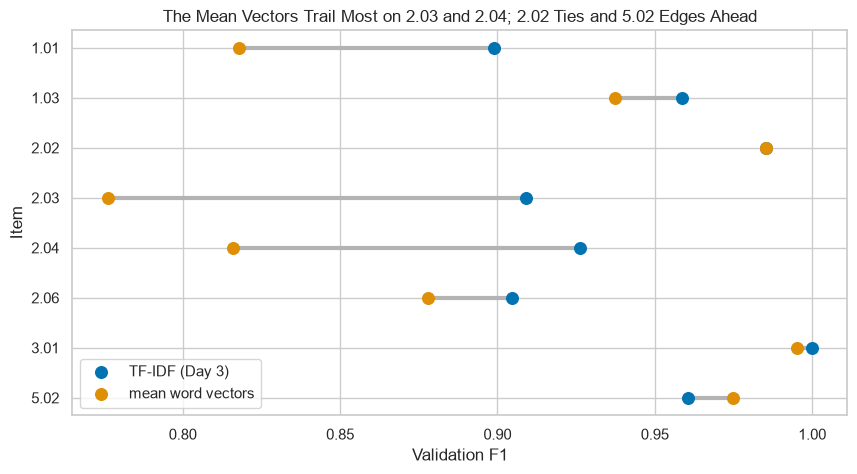

In [33]:
# each item's F1 for the two models, joined by a line
f1_tfidf = f1_score(valid["item"], tfidf_assigned, labels=LABELS, average=None)
f1_vectors = f1_score(valid["item"], vector_assigned, labels=LABELS, average=None)
plt.hlines(LABELS, f1_vectors, f1_tfidf, color="0.7", lw=3)
plt.scatter(f1_tfidf, LABELS, s=70, label="TF-IDF (Day 3)", zorder=3)
plt.scatter(f1_vectors, LABELS, s=70, label="mean word vectors", zorder=3)
plt.gca().invert_yaxis()
plt.legend(loc="lower left")
plt.xlabel("Validation F1")
plt.ylabel("Item")
plt.title("The Mean Vectors Trail Most on 2.03 and 2.04; 2.02 Ties and 5.02 Edges Ahead")
plt.show()

In [34]:
# the vector model's largest misassignments: the filer's item, the item it assigns, how many
matrix = confusion_matrix(valid["item"], vector_assigned, labels=LABELS)
np.fill_diagonal(matrix, 0)
misses = pd.DataFrame(matrix, index=LABELS, columns=LABELS).stack()
print(misses.sort_values(ascending=False, kind="stable").head(3).to_dict())

{('2.04', '2.03'): 11, ('2.03', '1.01'): 10, ('2.03', '2.04'): 10}


The vectors' misses gather where Day 3's did, among 2.03, 2.04 and 1.01.

## Where the Two Models Agree

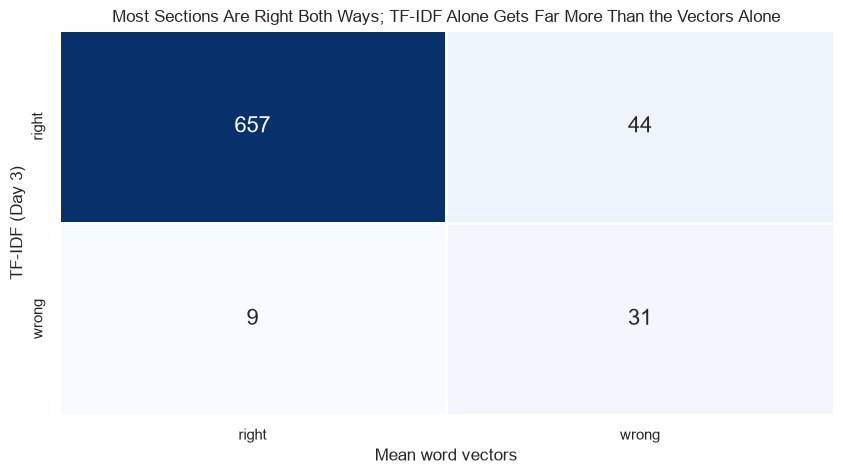

25 of the 31 both get wrong take the same wrong item


In [35]:
# each validation section by which model gets its item right
tfidf_right = tfidf_assigned == valid["item"]
vector_right = vector_assigned == valid["item"]
grid = pd.crosstab(np.where(tfidf_right, "right", "wrong"), np.where(vector_right, "right", "wrong"))
sns.heatmap(grid, annot=True, fmt="d", cmap="Blues", cbar=False, annot_kws={"size": 16}, linewidths=1)
plt.xlabel("Mean word vectors")
plt.ylabel("TF-IDF (Day 3)")
plt.title("Most Sections Are Right Both Ways; TF-IDF Alone Gets Far More Than the Vectors Alone")
plt.show()
both_wrong = ~tfidf_right & ~vector_right
print((both_wrong & (tfidf_assigned == vector_assigned)).sum(), "of the", both_wrong.sum(), "both get wrong take the same wrong item")

**On these rows 100 general-English numbers trail 40,403 counted columns: Day 3's TF-IDF model stays the course's 8-K classifier, and the next two sections look for where the numbers come up short.**

# What the Vectors Miss

## Tokens of the Indenture With No Row

In [36]:
# every token of the indenture, the ones with no row, and the ten most frequent of those
boyd_tokens = tokenize(boyd)
no_row = Counter(token for token in boyd_tokens if token not in index_of)
# (.total() adds up a Counter's counts)
print(len(boyd_tokens), "tokens |", no_row.total(), "with no row,", len(no_row), "distinct |", f"share {no_row.total() / len(boyd_tokens):.4f}")

63810 tokens | 422 with no row, 137 distinct | share 0.0066


{'number': 63, 'possessive': 132, 'own word': 172, 'hyphenated': 55}


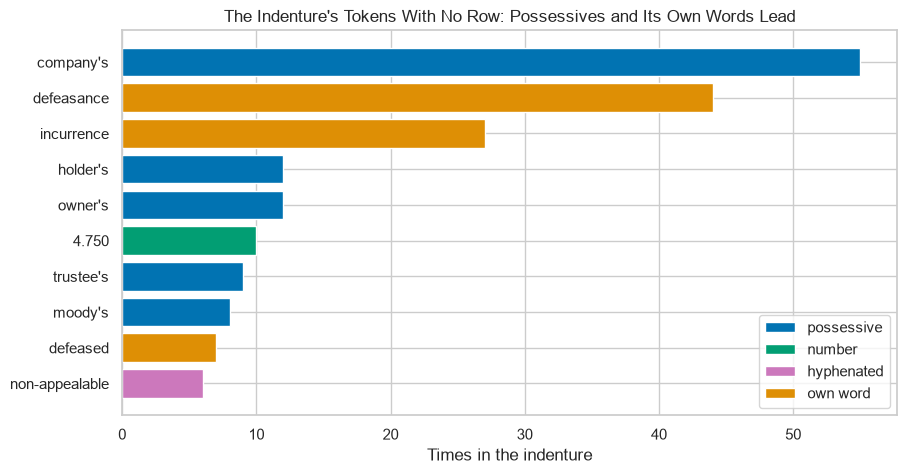

Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495.


In [37]:
# source text: quoted as published
# the kind of each token with no row, and the ten most frequent as bars coloured by kind
def kind(token):
    """possessive, number, hyphenated or the indenture's own word."""
    if token.endswith("'s"):
        return "possessive"
    if re.search(r"\d", token):
        return "number"
    return "hyphenated" if "-" in token else "own word"


kinds = Counter()
for token, times in no_row.items():
    kinds[kind(token)] += times
print(dict(kinds))
top = no_row.most_common(10)[::-1]
kind_colour = {"possessive": "C0", "number": "C2", "hyphenated": "C4", "own word": "C1"}
# one set of bars per kind, each bar at its token's row, so the legend names the kinds
for name, c in kind_colour.items():
    rows = [k for k, (token, _) in enumerate(top) if kind(token) == name]
    plt.barh(rows, [top[k][1] for k in rows], color=c, label=name)
plt.yticks(range(len(top)), [token for token, _ in top])
plt.legend(loc="lower right")
plt.xlabel("Times in the indenture")
plt.title("The Indenture's Tokens With No Row: Possessives and Its Own Words Lead")
plt.show()
boyd_source()

The course's file keeps every word of the course's texts that GloVe holds, so a token with no row here has none in all 400,000 words of GloVe.

"defeasance" and "incurrence" are the contract's own words, absent from general English.

## Defined Terms

In [38]:
# Day 1's defined terms of Section 1.01, and the ones holding a token with no row
definitions = boyd[sections.loc["1.01", "start"]:sections.loc["1.01", "end"]]
terms = defined_terms(definitions)
lost = [term for term in terms["term"] if any(token not in index_of for token in tokenize(term))]
print(len(terms), "terms |", len(lost), "hold a token with no row:", lost)

136 terms | 3 hold a token with no row: ['Defeased Indebtedness', "Moody's", 'QIB']


Almost every defined term's words have a row, but no row holds a definition: "Indebtedness" gets the row of the everyday word.

## Capitals Lower-Cased

In [39]:
# source text: quoted as published
# Section 4.12's tokens as written (Day 1's pattern with capitals allowed), and those that start with a capital
# (.isupper() is True for a capital letter)
as_written = re.findall(r"[A-Za-z0-9]+(?:[-'.][A-Za-z0-9]+)*", section_412)
capitals = Counter(token for token in as_written if token[0].isupper())
print(len(as_written), "tokens |", capitals.total(), "start with a capital")
boyd_source("4.12")

1840 tokens | 374 start with a capital
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495, Section 4.12.


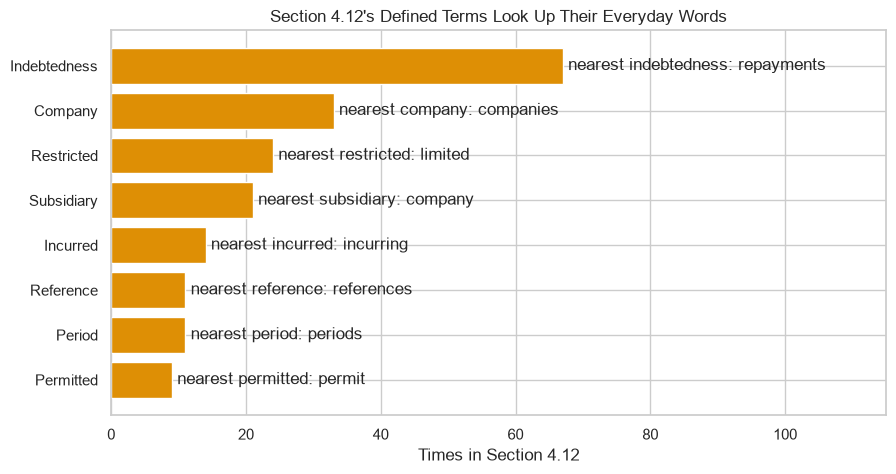

In [40]:
# the eight most frequent capitalised tokens, each with the nearest word of its lower-case form at the bar's end
top = capitals.most_common(8)
plt.barh([token for token, _ in top][::-1], [times for _, times in top][::-1], color="C1")
for k, (token, times) in enumerate(top[::-1]):
    plt.text(times + 0.8, k, f"nearest {token.lower()}: {nearest_words(token.lower(), 1)[0][0]}", va="center")
plt.xlim(0, 115)
plt.xlabel("Times in Section 4.12")
plt.title("Section 4.12's Defined Terms Look Up Their Everyday Words")
plt.show()

In [41]:
# one more lower-cased word of the indenture
print("notes", nearest_words("notes"))

notes [('note', 0.836), ('letters', 0.699), ('write', 0.692), ('written', 0.689), ('books', 0.663)]


"notes" sits with letters and books, never with debt.

In these vectors the five nearest words of "lien" are family names and initials from news text: the word's company in general English is not the contract's.

**Uncased vectors give a defined term the row of its everyday word.**

# What Averaging Loses

## Word Order

In [42]:
# two sentences with the same words in another order, and their mean vectors
first, _ = document_vector("the trustee may remove the company")
second, _ = document_vector("the company may remove the trustee")
print(np.array_equal(first, second))

True


The two sentences give the same mean exactly: an average loses **word order**, as Day 2's bag of words did.

**Predict 5**

Q. Section 4.12, the debt covenant, is 1,840 tokens long. Which word sits nearest its mean vector? Write down one word.

## The Mean of Section 4.12

In [43]:
# the five words nearest the section's mean vector, ties broken by the word
mean_412, _ = document_vector(section_412)
cosines = unit @ mean_412 / np.linalg.norm(mean_412)
order = np.lexsort((words, -cosines))[:5]
print([(words[row], round(float(cosines[row]), 3)) for row in order])

# how often "the" appears, and the share of stop words
tokens_412 = tokenize(section_412)
print(tokens_412.count("the"), "of", len(tokens_412), "tokens are the |",
      f"stop words {np.mean([token in ENGLISH_STOP_WORDS for token in tokens_412]):.4f}")

[('this', 0.899), ('the', 0.895), ('same', 0.894), ('only', 0.882), ('for', 0.878)]
145 of 1840 tokens are the | stop words 0.4984


Every token gets the same vote, so the words a covenant shares with every text pull the mean to them.

The mean is a **centroid**: the centre of the token rows.
The next picture draws each token in a plane fitted to the text's own rows, with a spoke to the centre.

In [44]:
# source text: quoted as published
# the opening clause of Section 4.12, its tokens, and the word nearest their mean
clause = section_412.split("\n")[1][4:].split(";")[0]
print(clause)
boyd_source("4.12")
clause_mean, _ = document_vector(clause)
clause_cosines = unit @ clause_mean / np.linalg.norm(clause_mean)
clause_nearest = words[np.lexsort((words, -clause_cosines))[0]]
print(len(tokenize(clause)), "tokens | nearest the mean:", clause_nearest)

The Company shall not, and shall not permit any Restricted Subsidiary to, Incur any Indebtedness
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495, Section 4.12.
15 tokens | nearest the mean: not


In [45]:
# centroid spokes (demonstration of the plane): each token at its own place, numbered by position, a spoke to the mean
# (each token is labelled with its positions in each order of the words, the orders split by a bar)
def draw_spokes(ax, orders, moved={}):
    """One text's tokens in a plane fitted to their rows, each with a spoke to the mean, drawn as a star."""
    tokens = tokenize(orders[0])
    rows = vectors[[index_of[token] for token in tokens]].astype(np.float64)
    plane = PCA(n_components=2).fit(rows)
    points, centre = plane.transform(rows), plane.transform([rows.mean(axis=0)])[0]
    for x, y in points:
        ax.plot([x, centre[0]], [y, centre[1]], color="0.75", lw=1)
    ax.scatter(*points.T, s=50, color="C0", zorder=3)
    ax.scatter(*centre, marker="*", s=420, color="C3", zorder=4, label="the mean (centroid)")
    # each distinct token once (Day 3's pd.unique), taken from left to right, its label above or below by turns
    # unless moved says where
    distinct = sorted(pd.unique(np.array(tokens)), key=lambda token: points[tokens.index(token), 0])
    for n, token in enumerate(distinct):
        numbers = [",".join(str(k) for k, t in enumerate(tokenize(order), start=1) if t == token) for order in orders]
        ax.annotate(f"{token} {' | '.join(numbers)}", points[tokens.index(token)],
                    xytext=moved.get(token, (9, 7 if n % 2 == 0 else -17)), textcoords="offset points", fontsize=11)
    ax.set(xlabel="First direction of the plane", ylabel="Second direction of the plane")
    ax.margins(0.15)
    return tokens, points

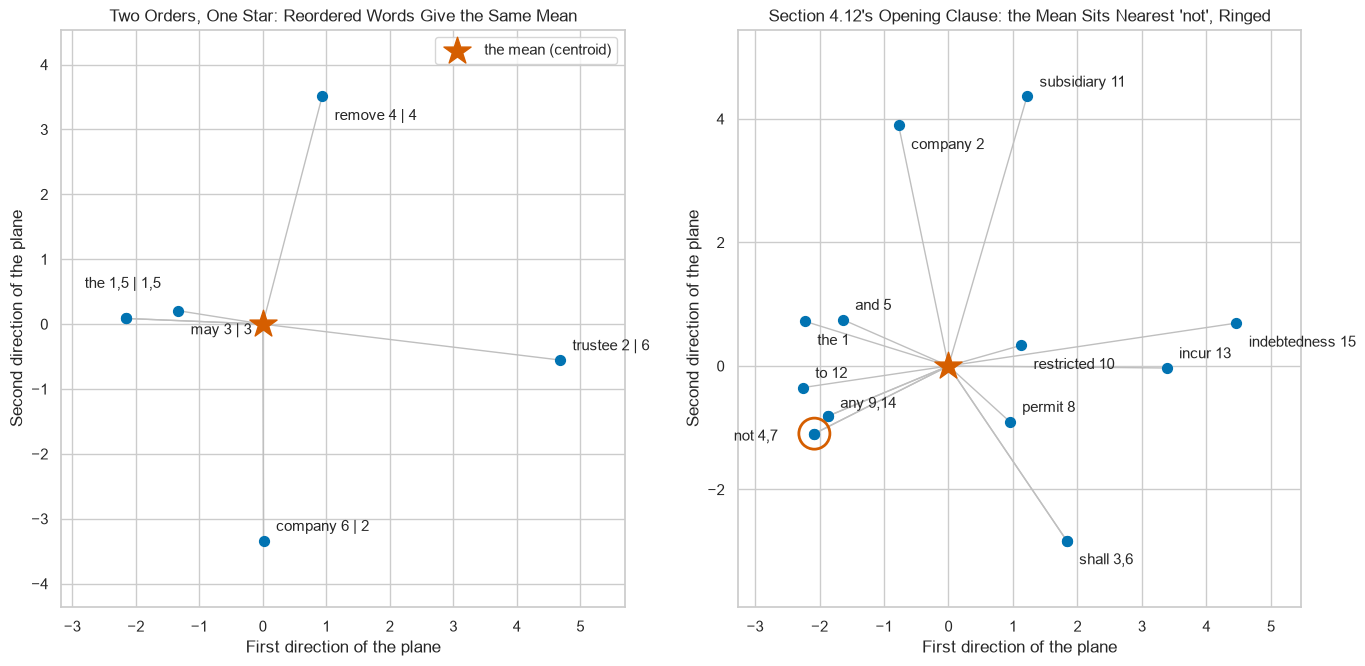

In [46]:
# left, the two orders of one sentence; right, 4.12's opening clause with the word nearest its mean ringed
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))
draw_spokes(axes[0], ["the trustee may remove the company", "the company may remove the trustee"], moved={"the": (-30, 22)})
tokens, points = draw_spokes(axes[1], [clause], moved={"not": (-58, -5), "any": (9, 6)})
axes[1].scatter(*points[tokens.index(clause_nearest)], s=500, facecolor="none", edgecolor="C3", lw=2, zorder=4)
axes[0].legend(loc="upper right")
axes[0].set_title("Two Orders, One Star: Reordered Words Give the Same Mean")
axes[1].set_title(f"Section 4.12's Opening Clause: the Mean Sits Nearest {clause_nearest!r}, Ringed")
plt.show()

Left: the second order only renumbers the same points, so the star does not move.

Right: the star sits among the clause's short words, which outnumber its defined terms.

**A mean gives "the" the same vote as "Indebtedness"; Day 2's IDF weighed them the other way.**

# Where Word Vectors Come From

## Counting Neighbours

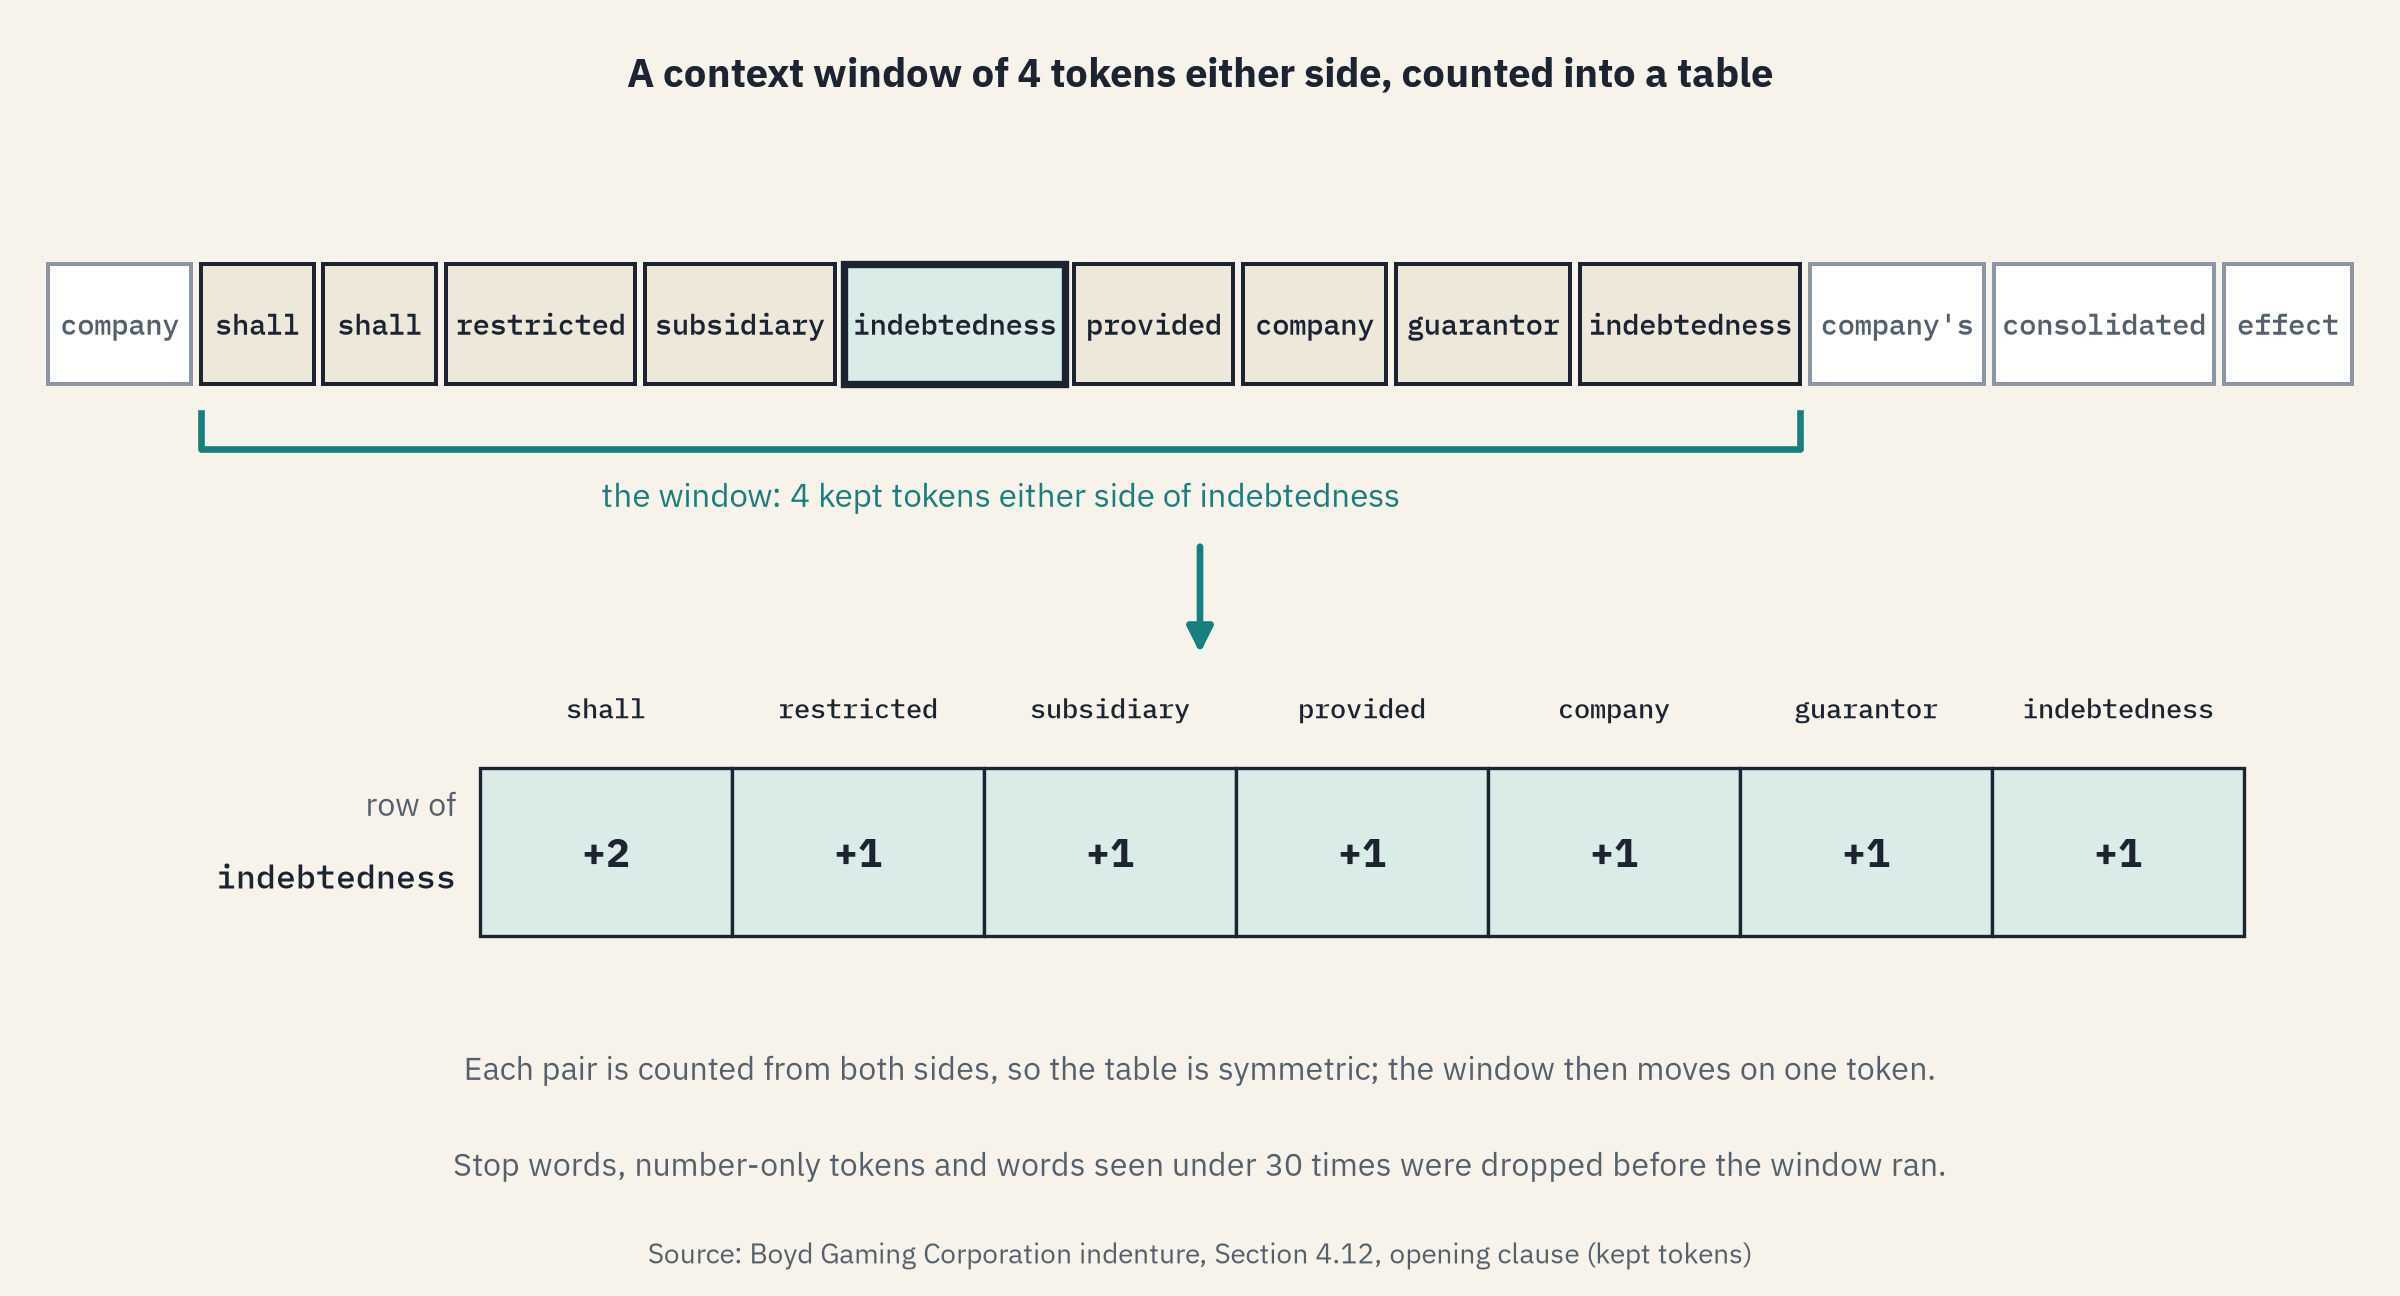

GloVe's rows were fitted to how often words appear near each other in billions of words.
The same counting on one document shows what that one document makes of its words: a **co-occurrence count** adds 1 for each pair of tokens within a **context window**, here 4 tokens either side.

In [47]:
# the indenture's content tokens (stop words and number-only tokens dropped), and the words seen 30 times or more
content = [token for token in boyd_tokens if token not in ENGLISH_STOP_WORDS and not re.fullmatch(r"[0-9]+(?:[-'.][0-9]+)*", token)]
seen = Counter(content)
vocab = sorted([word for word, times in seen.items() if times >= 30], key=lambda word: (-seen[word], word))
position_of = {word: k for k, word in enumerate(vocab)}
kept = [position_of[token] for token in content if token in position_of]
print(len(content), "content tokens |", len(vocab), "words seen 30 times or more |", len(kept), "tokens kept")

30525 content tokens | 207 words seen 30 times or more | 18767 tokens kept


In [48]:
# every pair of kept tokens within 4 positions adds 1, from each side, to a table of counts
table = np.zeros((len(vocab), len(vocab)))
for i in range(len(kept)):
    for j in range(max(0, i - 4), min(len(kept), i + 5)):
        if j != i:
            table[kept[i], kept[j]] += 1
print(int(table.sum()), "counts, the same table read from either side:", np.array_equal(table, table.T))

150116 counts, the same table read from either side: True


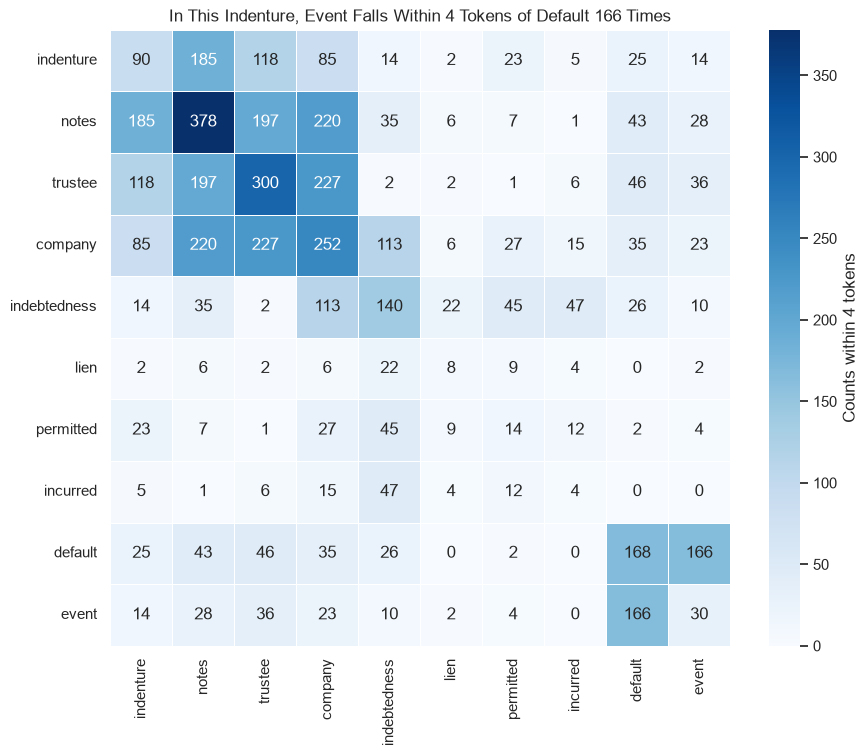

In [49]:
# ten of the words, and their counts with each other
shown = ["indenture", "notes", "trustee", "company", "indebtedness", "lien", "permitted", "incurred", "default", "event"]
picked = [position_of[word] for word in shown]
plt.figure(figsize=(10, 8))
sns.heatmap(pd.DataFrame(table[np.ix_(picked, picked)].astype(int), index=shown, columns=shown), annot=True, fmt="d",
            cmap="Blues", cbar_kws={"label": "Counts within 4 tokens"}, linewidths=0.5)
plt.title("In This Indenture, Event Falls Within 4 Tokens of Default 166 Times")
plt.show()

## The Indenture's Own Neighbours

Each word's row of counts is a vector too, and Day 2's cosine compares them.

In [50]:
# the count rows at length 1, and GloVe's unit rows for the words of the 207 that GloVe holds
count_unit = table / np.linalg.norm(table, axis=1, keepdims=True)
held = [word for word in vocab if word in index_of]
glove_unit = unit[[index_of[word] for word in held]]
print(len(held), "of the", len(vocab), "words have a GloVe row")


def nearest_in(rows, names, word, k=3):
    """The k nearest of a list of words in a table of their unit rows, ties broken by the word."""
    cosines = rows @ rows[names.index(word)]
    order = np.lexsort((names, -cosines))
    order = order[order != names.index(word)][:k]
    return [(names[row], round(float(cosines[row]), 3)) for row in order]


for word in ["covenant", "default", "indebtedness", "lien"]:
    print(word, "| counts:", nearest_in(count_unit, vocab, word), "| GloVe:", nearest_in(glove_unit, held, word))

205 of the 207 words have a GloVe row
covenant | counts: [('defeasance', 0.884), ('legal', 0.84), ('section', 0.613)] | GloVe: [('covenants', 0.535), ('clause', 0.415), ('obligation', 0.413)]
default | counts: [('occurred', 0.884), ('event', 0.841), ('relating', 0.621)] | GloVe: [('credit', 0.625), ('payment', 0.56), ('payments', 0.492)]
indebtedness | counts: [('permitted', 0.842), ('incurred', 0.816), ('b', 0.806)] | GloVe: [('incurred', 0.544), ('payable', 0.482), ('payments', 0.474)]
lien | counts: [('indebtedness', 0.749), ('liens', 0.73), ('permitted', 0.71)] | GloVe: [('president', 0.395), ('securities', 0.347), ('holders', 0.327)]


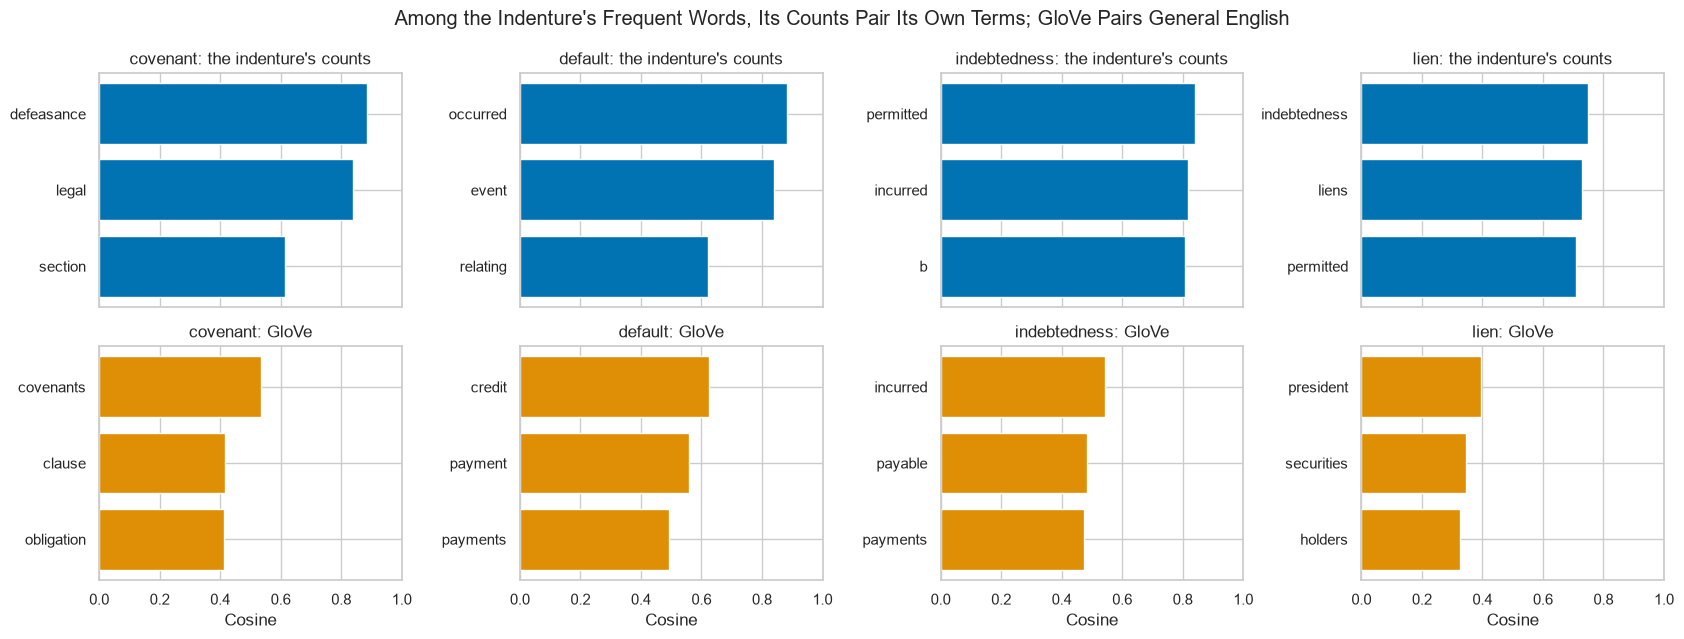

In [51]:
# the same four words, nearest three in the indenture's counts beside nearest three in GloVe
fig, axes = plt.subplots(2, 4, figsize=(17, 6.5), sharex=True)
for column, word in enumerate(["covenant", "default", "indebtedness", "lien"]):
    for row, (name, rows, names) in enumerate([("the indenture's counts", count_unit, vocab), ("GloVe", glove_unit, held)]):
        pairs = nearest_in(rows, names, word)
        axes[row, column].barh([near for near, _ in pairs][::-1], [cosine for _, cosine in pairs][::-1], color=f"C{row}")
        axes[row, column].set(title=f"{word}: {name}", xlim=(0, 1))
    axes[1, column].set_xlabel("Cosine")
fig.suptitle("Among the Indenture's Frequent Words, Its Counts Pair Its Own Terms; GloVe Pairs General English")
plt.tight_layout()
plt.show()

In the indenture's counts "covenant" sits by "defeasance", from "Covenant Defeasance", and "default" by "occurred" and "event", from "Event of Default".

GloVe, over the same words, keeps its general-English company.

> STORY: Where these vectors come from.
> GloVe, "Global Vectors for Word Representation", was published by Jeffrey Pennington, Richard Socher and Christopher D. Manning at the EMNLP conference in Doha in October 2014, pages 1532 to 1543.
> The paper describes a model that "trains on global word-word co-occurrence counts", the counting above at the scale of a corpus.
> For the 6 billion token corpus, a 2014 Wikipedia dump with Gigaword 5, the authors "tokenize and lowercase each corpus" and keep "the 400,000 most frequent words".
> The paper sets its results beside the word2vec tool, from Mikolov, Chen, Corrado and Dean's "Efficient Estimation of Word Representations in Vector Space" (arXiv, January 2013).
> Stanford NLP's repository says the pre-trained vectors "are made available under the Public Domain Dedication and License".
> Sources: the ACL Anthology, https://aclanthology.org/D14-1162/ and https://aclanthology.org/D14-1162.pdf; Stanford NLP, https://github.com/stanfordnlp/GloVe; arXiv, https://arxiv.org/abs/1301.3781 (all read 2026-11-18)

**Vectors describe the text they were counted from: the indenture's own counts pair "covenant" with "defeasance" and "default" with "event", and general English does not.**

# Insights and Conclusion

"bond" sits by "bonds" and "treasury"; "covenant" by "lutheran" and "charter".

On the map 28 of 33 arrows stay in their group, and four of the five that leave start at a legal word.

Analogy arithmetic always returns a nearest word, whatever it is.

0.0066 of the indenture's tokens and about 0.019 of an 8-K section's have no row, and defined terms lose their capitals.

The mean vectors score a validation macro F1 of 0.8976 against Day 3's 0.9429; TF-IDF alone gets 44 sections right that the vectors miss, the vectors alone 9.

A mean loses word order, and "the" outvotes the defined terms.

The indenture's own counts give it its own neighbours.

**General-English vectors place the market's words together and scatter the contract's; Day 6 turns whole sentences into vectors with a model made for them.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Load pretrained word vectors from an `.npz` file and look a word up.
* List a word's nearest words by cosine, ties broken by the word.
* Draw words on a map with an arrow to each word's nearest neighbour.
* Do arithmetic on word vectors and read the result with care.
* Count the tokens of a document that have no vector, by kind.
* Turn each section into its mean word vector and set a classifier on it beside Day 3's.
* Count which words sit near each other in one document.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [52]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**Two Words of the Contract**

Q. Store the five nearest words of "indenture", words only, in a list `ex1_indenture`. Store the nearest word of "trustee" in `ex1_trustee_top`, and their cosine from `unit`, unrounded, in `ex1_trustee_cosine`.

In [53]:
# the five nearest words of indenture, words only; the nearest of trustee and its unrounded cosine
ex1_indenture = [word for word, _ in nearest_words("indenture")]
ex1_trustee_top = nearest_words("trustee", 1)[0][0]
ex1_trustee_cosine = float(unit[index_of["trustee"]] @ unit[index_of[ex1_trustee_top]])
print(ex1_indenture, "|", ex1_trustee_top, f"{ex1_trustee_cosine:.4f}")

['indentures', 'exclusivity', 'seven-year', 'noncompete', 'ten-year'] | trustees 0.7657


In [54]:
check("Exercise 1 nearest words of indenture", ex1_indenture, ['indentures', 'exclusivity', 'seven-year', 'noncompete', 'ten-year'])
check("Exercise 1 nearest word of trustee", ex1_trustee_top, 'trustees')
check("Exercise 1 their cosine", ex1_trustee_cosine, 0.7656753396442938)

Exercise 1 nearest words of indenture: correct
Exercise 1 nearest word of trustee: correct
Exercise 1 their cosine: correct


### Exercise 2

**The Mean Without Stop Words**

Q. Build the training and validation mean vectors again with every token in `ENGLISH_STOP_WORDS` dropped before the mean, fit the vector model's settings (`C=10, max_iter=10_000, tol=1e-10`), and store the validation macro F1 in `ex2_f1`. Print it at 3 decimals.

In [55]:
# the mean vectors with every stop word dropped first, then the vector model's settings
def content_vector(text):
    """The mean word vector of a text's tokens that have a row and are not stop words."""
    found = [index_of[token] for token in tokenize(text) if token in index_of and token not in ENGLISH_STOP_WORDS]
    return vectors[found].astype(np.float64).mean(axis=0)


ex2_train = np.array([content_vector(text) for text in train["text"]])
ex2_valid = np.array([content_vector(text) for text in valid["text"]])
ex2_model = LogisticRegression(C=10, max_iter=10_000, tol=1e-10).fit(ex2_train, train["item"])
ex2_f1 = f1_score(valid["item"], ex2_model.predict(ex2_valid), average="macro")
print(f"validation macro F1 without stop words {ex2_f1:.3f}")

validation macro F1 without stop words 0.889


In [56]:
check("Exercise 2 macro F1 without stop words", ex2_f1, 0.8885498281964004)

Exercise 2 macro F1 without stop words: correct


### Exercise 3

**The Odd One Out**

Q. Write `odd_one_out(chosen)`, which returns the word of a list with the lowest mean cosine to the others, from `unit`. Store `odd_one_out(["bond", "loan", "debt", "covenant", "credit"])` in `ex3_first` and `odd_one_out(["coupon", "maturity", "yield", "collateral", "spread"])` in `ex3_second`.

In [57]:
def odd_one_out(chosen):
    """The word of a list with the lowest mean cosine to the other words."""
    rows = unit[[index_of[word] for word in chosen]]
    mean_cosine = ((rows @ rows.T).sum(axis=1) - 1) / (len(chosen) - 1)
    return chosen[int(np.argmin(mean_cosine))]


ex3_first = odd_one_out(["bond", "loan", "debt", "covenant", "credit"])
ex3_second = odd_one_out(["coupon", "maturity", "yield", "collateral", "spread"])
print(ex3_first, ex3_second)

covenant collateral


In [58]:
check("Exercise 3 the odd one out of the first list", ex3_first, 'covenant')
check("Exercise 3 the odd one out of the second list", ex3_second, 'collateral')

Exercise 3 the odd one out of the first list: correct
Exercise 3 the odd one out of the second list: correct


### Exercise 4: AI check

**A Share That Looks Small**

You asked an AI assistant for a function that gives a text's mean GloVe vector and the share of its tokens GloVe lacks.
This came back.
Before you run the test below, write down the share you expect for Section 4.12, then find the one bug.

In [59]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def text_vector(text):
    """The mean GloVe vector of a text, and the share of its tokens GloVe does not hold."""
    tokens = re.findall(r"[A-Za-z0-9]+(?:[-'.][A-Za-z0-9]+)*", normalize_text(text))
    found = [token for token in tokens if token in index_of]
    missing = [token for token in found if token not in index_of]
    return vectors[[index_of[token] for token in found]].astype(np.float64).mean(axis=0), len(missing) / len(found)

In [60]:
# the docstring's promise, tested: the share on Section 4.12 and on one sentence, with the tokens it used
_, share = text_vector(section_412)
print(f"Section 4.12: share missing {share:.4f} | tokens used", len([t for t in as_written if t in index_of]), "of", len(tokenize(section_412)))
sentence = "The Company's Notes are subject to defeasance under the Indenture."
_, share = text_vector(sentence)
print(f"the sentence: share missing {share:.4f} | tokens used", [t for t in re.findall(r"[A-Za-z0-9]+(?:[-'.][A-Za-z0-9]+)*", sentence) if t in index_of])

Section 4.12: share missing 0.0000 | tokens used 1458 of 1840
the sentence: share missing 0.0000 | tokens used ['are', 'subject', 'to', 'under', 'the']


By hand, the sentence has 10 tokens, and "company's" and "defeasance" have no row: 2 of 10.

Q. Fix the one wrong idea: look the tokens up as Day 1's `tokenize` writes them and count the missing share over every token. Store the share for Section 4.12 in `ex4_missing`.

In [61]:
# the fix: Day 1's lower-case tokens, and the share missing counted over every token
def text_vector(text):
    """The mean GloVe vector of a text, and the share of its tokens GloVe does not hold."""
    tokens = tokenize(text)
    found = [token for token in tokens if token in index_of]
    return vectors[[index_of[token] for token in found]].astype(np.float64).mean(axis=0), 1 - len(found) / len(tokens)


_, ex4_missing = text_vector(section_412)
_, sentence_share = text_vector(sentence)
print(f"Section 4.12: share missing {ex4_missing:.4f} | the sentence: {sentence_share:.4f}")

Section 4.12: share missing 0.0114 | the sentence: 0.2000


In [62]:
check("Exercise 4 share missing in Section 4.12", ex4_missing, 0.011413043478260887)

Exercise 4 share missing in Section 4.12: correct


## Congratulations!

You loaded 44,558 words as rows of 100 numbers and measured how close two words sit in them.
You drew a map of desk words, did arithmetic on vectors, and counted what the vectors miss in a real indenture.
You turned every 8-K section into 100 numbers and set Day 3's classifier on them, beside Day 3's own model.
Then you counted one document's own neighbours and saw where the vectors come from.
Day 5 is the week's case study, on the FOMC statements, with every tool of the week.

[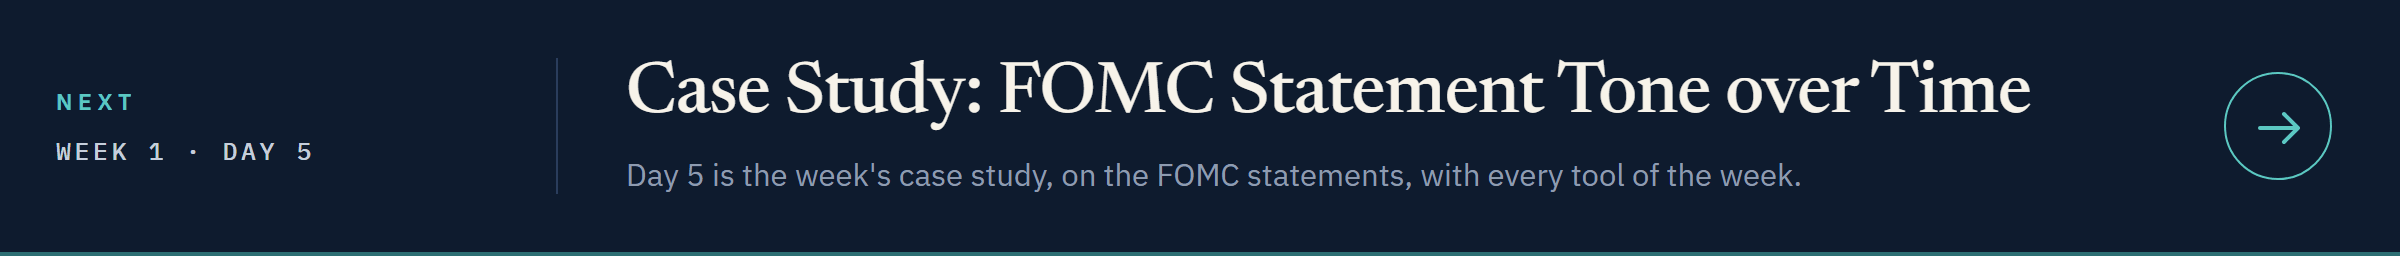](../day5/05_case_study_fomc_statement_tone_over_time.ipynb)

[Open Day 5 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course07_nlp_and_llms/week1/day5/05_case_study_fomc_statement_tone_over_time.ipynb)